# Heart Sound Classification: an end-to-end ML pipeline (normal vs abnormal)

**Problem.** Can a computer listen to a stethoscope recording (a *phonocardiogram*) and flag it as **normal** or **abnormal**?
This could help screen patients where cardiologists are scarce. It is an educational prototype, **not a medical device**.

**Data.** PhysioNet/CinC Challenge 2016: 3,240 heart-sound recordings (about 5 to 120 seconds each, 2000 Hz) from six sources (a to f), labelled normal or abnormal.
This is **audio, not tabular data**: each recording is turned into a spectrogram image and classified with a CNN.

**Pipeline in this notebook**
1. Acquire the data, 2. explore it (and listen to it), 3. preprocess audio into spectrogram clips (`src/preprocessing.py`),
4. split by recording without leakage, 5. compare simple baselines with a CNN (`src/model.py`),
6. optimize and evaluate (4+ metrics, per-source results, one final test), 7. save the model, 8. prediction function (`src/prediction.py`),
9. check that retraining works. The API, UI, Docker, load test and deployment live in the rest of the repository (see README).

**How to read this notebook.** Every step has three parts: a markdown cell saying *what the code does and why*, the code cell, and a markdown cell on *how to read the result*.
Run the cells in order. 

**Rules followed in every step:** the test set is used once at the very end; anything learned from data (scalers, thresholds, model choice) is learned on training/validation data only;
no feature comes from the label itself; per-source results are reported because the source can be a shortcut.

## Step 1. Set up the environment

**What this cell does:** installs the audio libraries, imports everything we need, fixes the random seed so results can be repeated,
and creates the folders `data/`, `models/`, `src/` and `outputs/`.

**Key terms**
- **librosa / soundfile:** Python libraries to read audio and compute spectrograms.
- **Seed:** a fixed starting number for the random generators, so a rerun gives the same split and similar training results.

**Why:** a notebook that is not reproducible cannot be trusted or graded. (If you run it locally from the `notebook/` folder, the first lines switch to the repository root so `src/`, `models/` and `data/` end up in the right place.)

In [1]:
%pip install -q librosa soundfile
import os, random, json, shutil, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, librosa.display
import soundfile as sf
import tensorflow as tf

warnings.filterwarnings("ignore")
if os.path.basename(os.getcwd()) == "notebook":          # running locally from the notebook/ folder: work from the repo root
    os.chdir("..")

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

for folder in ["data", "models", "src", "outputs"]:
    os.makedirs(folder, exist_ok=True)
open("src/__init__.py", "a").close()          # makes src/ importable as a package

print("TensorFlow", tf.__version__, "| librosa", librosa.__version__, "| GPU available:", bool(tf.config.list_physical_devices("GPU")))

Note: you may need to restart the kernel to use updated packages.
TensorFlow 2.21.0 | librosa 1.0.1 | GPU available: False


## Step 2. Download the data

**What this cell does:** copies the PhysioNet Challenge 2016 files from PhysioNet's public Amazon S3 bucket (the audio `.wav` files and the label files). It skips files we do not need (`.dat`, `.zip`, papers).
If the data is already there it does nothing.

**Why:** downloading file by file with `wget` takes hours (thousands of tiny files); `aws s3 sync` does it in minutes. `--no-sign-request` means no account is needed.

**Source and citation:** Liu et al. (2016), *An open access database for the evaluation of heart sound algorithms*, Physiological Measurement 37(12). Dataset page: physionet.org/content/challenge-2016/1.0.0/

In [2]:
import subprocess, sys, shutil

DATA_ROOT = os.environ.get("HEART_DATA_ROOT", "/content/heart_data" if os.path.isdir("/content") else "heart_data")

if os.path.isdir(f"{DATA_ROOT}/training-a"):
    print("Data already downloaded.")
else:
    try:
        import awscli                                   # the AWS command-line tool, used as a Python module (works on Windows too)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "awscli"], check=True)
    subprocess.run([sys.executable, "-m", "awscli", "s3", "sync", "--no-sign-request", "--only-show-errors",
                    "--exclude", "*.dat", "--exclude", "*.zip", "--exclude", "papers/*", "--exclude", "sources/*",
                    "s3://physionet-open/challenge-2016/1.0.0/", DATA_ROOT], check=True)

print(sorted(os.listdir(DATA_ROOT)))
total = sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(DATA_ROOT) for f in fs)
print(f"Total size on disk: {total / 1e6:.0f} MB")

['annotations', 'figure1.png', 'mathworks.png', 'training-a', 'training-b', 'training-c', 'training-d', 'training-e', 'training-f', 'validation']
Total size on disk: 325 MB


**Reading the output:** you should see the folders `training-a` to `training-f` (the labelled recordings) and `validation` (PhysioNet's own validation set), about 349 MB in total.
We will **ignore PhysioNet's `validation` folder**: it only repeats recordings that are already in the training folders, so using it would leak training data into evaluation.
We make our own train / validation / test split in Step 8.

## Step 3. Build one table with every recording and its label

**What this cell does:** for each of the six folders it reads two small label files, `REFERENCE.csv` (record name and label) and `REFERENCE-SQI.csv` (also a signal-quality flag), merges them, and adds the source letter and the path of the `.wav` file.
It then creates the column `abnormal` (**1 = abnormal, 0 = normal**; PhysioNet writes abnormal as `1` and normal as `-1`) and prints a summary per source.

**Key terms**
- **Source (a to f):** the research group / device that recorded the data. Sources differ a lot (equipment, patients, how often abnormal), so they can act as a *shortcut* for a model.
- **Signal quality (SQI):** 1 = good recording, 0 = poor (noisy). 

**Why:** one clean table (`df`) is the base for everything after: splitting, plotting and training. The `assert` lines stop the notebook if a file is missing or a record appears twice.

In [3]:
SOURCES = ["a", "b", "c", "d", "e", "f"]
frames = []
for s in SOURCES:
    folder = f"{DATA_ROOT}/training-{s}"
    ref = pd.read_csv(f"{folder}/REFERENCE.csv", header=None, names=["record", "label"])
    sqi = pd.read_csv(f"{folder}/REFERENCE-SQI.csv", header=None, names=["record", "label_sqi", "quality"])
    part = ref.merge(sqi[["record", "quality"]], on="record", how="left")
    part["source"] = s
    part["path"] = part["record"].apply(lambda r: f"{folder}/{r}.wav")
    frames.append(part)

df = pd.concat(frames, ignore_index=True)
df["abnormal"] = (df["label"] == 1).astype(int)          # 1 = abnormal, 0 = normal

assert df["record"].is_unique, "duplicate record names"
assert df["path"].apply(os.path.exists).all(), "some .wav files are missing"
assert df["quality"].notna().all(), "missing quality flag"

print(f"Recordings: {len(df)} | abnormal share: {df['abnormal'].mean():.1%} | poor quality: {(df['quality'] == 0).sum()}")
summary = df.groupby("source").agg(recordings=("record", "size"), abnormal=("abnormal", "sum"),
                                   abnormal_pct=("abnormal", lambda x: round(100 * x.mean(), 1)),
                                   poor_quality=("quality", lambda x: int((x == 0).sum())))
summary

Recordings: 3240 | abnormal share: 20.5% | poor quality: 364


,recordings,abnormal,abnormal_pct,poor_quality
source,,,,
a,409,292,71.4,17
b,490,104,21.2,122
c,31,24,77.4,4
d,55,28,50.9,3
e,2141,183,8.5,213
f,114,34,29.8,5


**What the output shows (real data):**
- **3,240 recordings**, about **20.5% abnormal**. The classes are **imbalanced**: a model that says "normal" every time would be right about 80% of the time and catch no disease. That is why we do not rely on accuracy alone and use recall, precision, F1 and AUC.
- **364 recordings are poor quality** (flag 0).
- **The sources are very different in size:** source `e` has 2,141 recordings (66%), while `c` has only 31 and `d` 55.
- **The abnormal rate depends strongly on the source:** for example source `a` is about 71% abnormal, while the overall rate is 20.5%. A model could learn "which source is this" instead of "is the heart abnormal". We handle this by stratifying the split by source and label, and by reporting results per source.

**Reading the table by source:**

| Source | Recordings | Abnormal | Poor quality | Reading |
|---|---|---|---|---|
| a | 409 | 71.4% | 17 (4%) | mostly **abnormal** |
| b | 490 | 21.2% | 122 (25%) | mostly normal, about the overall rate, **noisiest source** |
| c | 31 | 77.4% | 4 | mostly **abnormal**, but tiny |
| d | 55 | 50.9% | 3 | balanced, tiny |
| e | 2,141 | 8.5% | 213 (10%) | mostly **normal**, two thirds of all data |
| f | 114 | 29.8% | 5 | mostly normal |

- **Mostly abnormal:** sources a (71%) and c (77%). **Mostly normal:** e (8.5%), f (30%) and b (21%). Source d is about half and half.

- The overall 20.5% hides a huge range, from 8.5% (e) to 77% (c). The two big sources sit at opposite ends: a is about 8 times more abnormal than e.

- **Poor-quality recordings are not spread evenly either:** a quarter of source b is flagged poor quality, against 4% of source a. So "noisy recording" is another thing that could stand in for the source, which is why quality results are reported separately in Step 17.

- c and d have only 31 and 55 recordings, so their rates are very uncertain.

## Step 4. Look at (and listen to) one normal and one abnormal recording

**What this cell does:** loads one good-quality **normal** and one good-quality **abnormal** recording from source `a` (the same source, so the comparison is fair), prints each one's sample rate, length and number of samples, and plots the **waveform** of each.
It then adds audio players. Browsers cannot play 2000 Hz audio, so for *listening only* the sound is resampled to 8000 Hz; the data we analyse is untouched.

**Key terms**
- **Waveform:** the sound drawn as a line: time on the x-axis, amplitude (how strong the sound is) on the y-axis.
- **Sample rate:** measurements per second. 2000 Hz means 2000 numbers for every second of sound.

**Why:** before turning audio into images we must see what the raw signal looks like.

Normal: sample rate = 2000 Hz | duration = 35.7 s | samples = 71332
Abnormal: sample rate = 2000 Hz | duration = 35.7 s | samples = 71332


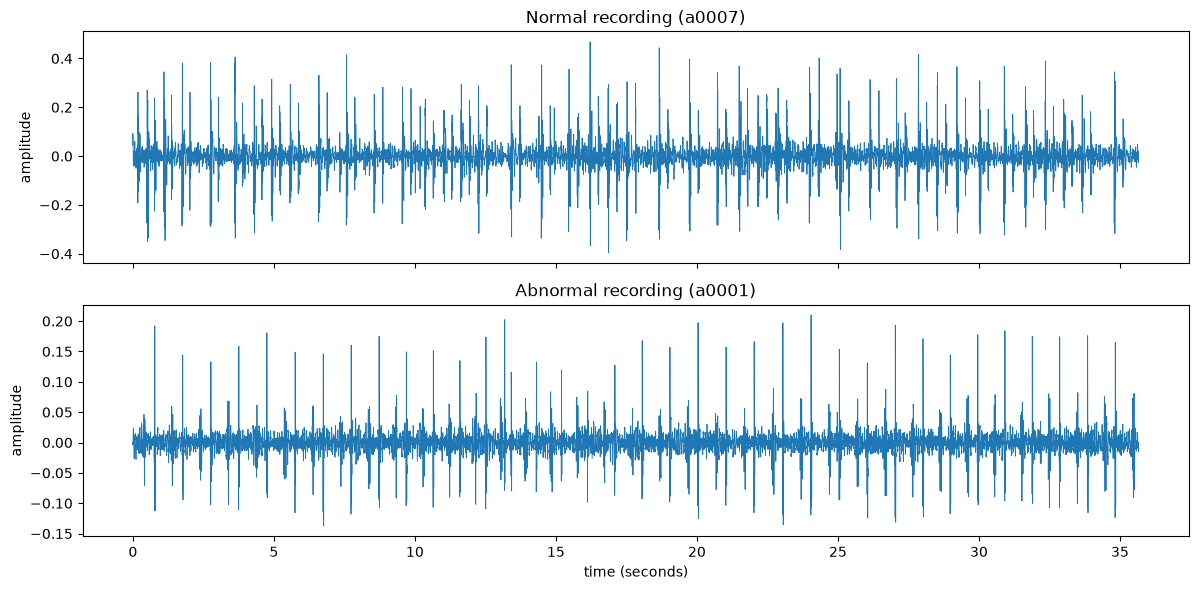

Listen: Normal


Listen: Abnormal


In [4]:
from IPython.display import Audio, display

good = df[df["quality"] == 1]
normal_row = good[(good["source"] == "a") & (good["abnormal"] == 0)].iloc[0]
abnormal_row = good[(good["source"] == "a") & (good["abnormal"] == 1)].iloc[0]

examples = {}
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, (name, row) in zip(axes, [("Normal", normal_row), ("Abnormal", abnormal_row)]):
    y, sr = librosa.load(row["path"], sr=None)            # sr=None keeps the file's own sample rate
    examples[name] = (y, sr)
    ax.plot(np.arange(len(y)) / sr, y, linewidth=0.6)
    ax.set_title(f"{name} recording ({row['record']})")
    ax.set_ylabel("amplitude")
    print(f"{name}: sample rate = {sr} Hz | duration = {len(y) / sr:.1f} s | samples = {len(y)}")
axes[1].set_xlabel("time (seconds)")
plt.tight_layout()
plt.show()

for name, (y, sr) in examples.items():                    # playback only: upsample to 8 kHz so browsers can play it
    y_play = librosa.resample(y, orig_sr=sr, target_sr=8000)
    y_play = y_play / np.max(np.abs(y_play))
    print(f"Listen: {name}")
    display(Audio(y_play, rate=8000))

**What the output shows (real data):**
- **Sample rate = 2000 Hz**; both recordings are **35.7 s** (71,332 samples). 35.7 s x 2000 Hz is about 71,332, so the numbers agree.
- **Both waveforms** show a flat, noisy baseline with sharp spikes that repeat regularly. Each spike is a heart sound; a normal beat has two main sounds ("lub-dub"), so the spikes come in pairs.
- **Normal vs abnormal look very similar** by eye. The raw waveform alone does not let us tell them apart.
- **Amplitude warning:** the normal recording peaks near 0.4 and the abnormal near 0.2. That does **not** mean abnormal hearts are quieter: loudness depends on the stethoscope, how hard it was pressed and the recording gain. Using loudness as a clue would be a shortcut, so we scale the volume of every clip later.

**Takeaway:** the waveform shows *when* beats happen but not *what the sounds are made of*. Murmurs add energy at certain pitches, and a spectrogram shows pitch over time.

## Step 5. Do all recordings have the same length and sample rate?

**What this cell does:** reads only the file *header* of every `.wav` (fast, no full audio loading) to get its sample rate and duration, summarises them overall and per source and per class, and draws a histogram of the durations for normal vs abnormal.

**Why:** a CNN needs every input to have the same size, so we must know if lengths and sample rates differ. We also check whether duration differs between classes: if it does, the model could learn recording length instead of heart sounds.

Sample rates found: {2000: 3240}

Duration (seconds), overall:
count    3240.0
mean       22.5
std        12.4
min         5.3
25%        12.9
50%        20.8
75%        30.6
max       122.0
Name: duration, dtype: float64

Duration by source:
         min  median    max
source                     
a        9.3    35.6   36.5
b        5.3     8.0    8.0
c        9.6    44.4  122.0
d        6.6    12.3   48.5
e        8.1    21.1  101.7
f       29.4    31.7   59.6

Median duration by class (0 = normal, 1 = abnormal):
abnormal
0    20.0
1    23.8
Name: duration, dtype: float64


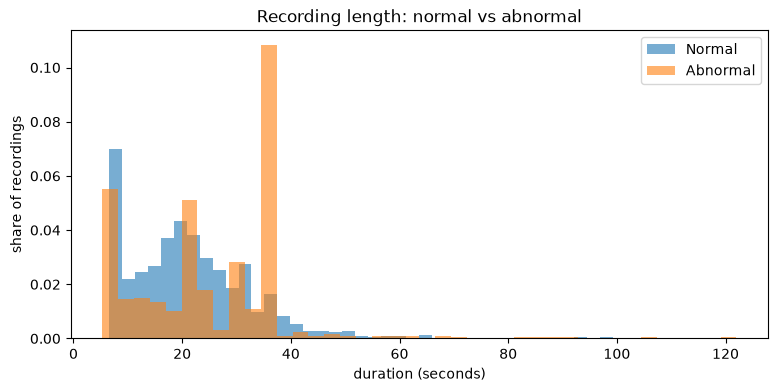

In [5]:
infos = [sf.info(p) for p in df["path"]]
df["sr"] = [i.samplerate for i in infos]
df["duration"] = [i.duration for i in infos]

print("Sample rates found:", df["sr"].value_counts().to_dict())
print("\nDuration (seconds), overall:")
print(df["duration"].describe().round(1))
print("\nDuration by source:")
print(df.groupby("source")["duration"].agg(["min", "median", "max"]).round(1))
print("\nMedian duration by class (0 = normal, 1 = abnormal):")
print(df.groupby("abnormal")["duration"].median().round(1))

plt.figure(figsize=(9, 4))
for flag, name in [(0, "Normal"), (1, "Abnormal")]:
    plt.hist(df[df["abnormal"] == flag]["duration"], bins=40, alpha=0.6, label=name, density=True)
plt.xlabel("duration (seconds)"); plt.ylabel("share of recordings")
plt.title("Recording length: normal vs abnormal"); plt.legend(); plt.show()

**What the output shows (real data):**
- **Sample rate:** all 3,240 recordings are 2000 Hz, so no resampling is needed.
- **Duration varies a lot:** from 5.3 s to 122 s (median 20.8 s). A CNN needs fixed-size input, so we will cut every recording into clips of one fixed length.
- **Duration depends on the source:** source `b` is always about 8 s, source `a` is mostly about 35 s, source `c` has a median of 44 s and one recording of 122 s.
- **Duration differs by class:** median 20.0 s for normal vs 23.8 s for abnormal. The big orange (abnormal) spike near 35 s is mostly source `a`, which is mostly abnormal.

**Why this matters (shortcut risk):** if the model learns "about 35 s long means abnormal" it reads the recording setup, not the heart. Fixed-length clips remove duration as a clue, and per-source results show whether the model works beyond one source.

## Step 6. Choose one fixed clip length

**What this cell does:** for three candidate clip lengths (3, 5 and 8 seconds) it counts how many recordings are too short for that length, and how many non-overlapping clips we would get.

**Why:** the clip must be long enough to contain several heartbeats (about 1 beat per second) and short enough that no recording is lost or padded with silence.

**Important rule for later:** one recording gives several clips. All clips from one recording must stay in the same split (train, validation or test). If clips of one recording were split between train and test, the model would be tested on audio it had effectively already seen (**data leakage**).

In [6]:
rows = []
for L in [3, 5, 8]:
    rows.append({"clip_length_s": L,
                 "recordings_shorter_than_L": int((df["duration"] < L).sum()),
                 "total_clips": int((df["duration"] // L).sum())})
print(pd.DataFrame(rows).to_string(index=False))

print("\nShortest recording in the dataset:", round(df["duration"].min(), 1), "s")
print("\nClips per recording at L = 5 s, by source:")
print((df["duration"] // 5).groupby(df["source"]).agg(["min", "median", "max"]).astype(int))

 clip_length_s  recordings_shorter_than_L  total_clips
             3                          0        22510
             5                          0        13015
             8                         18         7700

Shortest recording in the dataset: 5.3 s

Clips per recording at L = 5 s, by source:
        min  median  max
source                  
a         1       7    7
b         1       1    1
c         1       8   24
d         1       2    9
e         1       4   20
f         5       6   11


**What the output shows (real data):**
- 3 s and 5 s lose no recordings; **8 s is too short for 18 recordings**, so we rule it out.
- The shortest recording is **5.3 s**, so a 5 s clip fits every recording. We cannot go above 5 s without dropping or padding some recordings.
- **Decision: clip length = 5 seconds** (about 5 heartbeats). That gives 13,015 clips from 3,240 recordings.
- **Clips per recording is very uneven:** source `b` gives exactly 1, source `c` up to 24. If we used every clip, long recordings would dominate training.

**Consequences:** (1) split by **recording**, never by clip; (2) take at most a few clips per recording for training (we use 3); (3) at prediction time, cut a new recording into 5 s clips, predict each and **average** the probabilities.

## Step 7. The preprocessing module (`src/preprocessing.py`)

**What this cell does:** `%%writefile` saves the whole cell as the file `src/preprocessing.py`. This is the **same file the API and the UI import**, so training and prediction always preprocess audio identically.

**The pipeline for one recording**
1. `load_audio`: read the file as mono, 2000 Hz, then apply a **band-pass filter** (keep 25 to 900 Hz). This removes slow drift from hand movement / breathing and hiss near the top of the range: our fix for noisy audio.
2. `make_clips`: cut into non-overlapping **5 s clips** (pad with silence if shorter; keep at most `max_clips`, spread over the recording).
3. `to_melspec`: scale the volume of each clip, compute a **mel spectrogram** (40 frequency bands x 251 time steps) and convert it to decibels.
4. `scale_spec`: map the dB range (-80 to 0) to 0..1, the range a neural network likes.

Also in the file: `extract_features` (a few interpretable numbers for the data-insight plots), `quality_report` (warnings shown next to a prediction) and the fixed settings (`SR`, `CLIP_SECONDS`, `N_MELS`, ...). **If you change a setting, the model must be retrained.**

In [7]:
%%writefile src/preprocessing.py
"""Audio preprocessing for heart-sound (phonocardiogram) classification.

Pipeline for ONE recording:
    .wav file -> load (mono, 2000 Hz) -> band-pass filter (25-900 Hz)
              -> cut into non-overlapping 5 s clips -> mel spectrogram (dB)
              -> scale to 0..1 -> array of shape (n_clips, 40, 251, 1)

The same functions are used by the notebook, the API and the retraining code,
so training and prediction always see identical inputs.
"""
import numpy as np
import soundfile as sf
import librosa
from scipy.signal import butter, sosfiltfilt

# ---- fixed settings (changing any of these means the model must be retrained) ----
SR = 2000                      # sample rate used by the PhysioNet 2016 recordings (Hz)
CLIP_SECONDS = 5               # every model input is a 5 second clip
CLIP_SAMPLES = SR * CLIP_SECONDS
N_FFT = 256                    # spectrogram window (256 samples = 0.128 s)
HOP_LENGTH = 40                # window step (40 samples = 0.02 s)
N_MELS = 40                    # number of frequency bands
FMIN, FMAX = 20, 1000          # frequency range of the spectrogram (Hz)
BAND_LOW, BAND_HIGH = 25, 900  # band-pass filter range (Hz)
N_FRAMES = 1 + CLIP_SAMPLES // HOP_LENGTH      # 251 time steps
INPUT_SHAPE = (N_MELS, N_FRAMES, 1)            # (40, 251, 1)
DB_RANGE = 80.0                # dB values are kept between -80 and 0, then scaled to 0..1


def bandpass_filter(y, low=BAND_LOW, high=BAND_HIGH, sr=SR, order=4):
    """Remove very low drift (hand movement, breathing) and near-Nyquist hiss."""
    if len(y) < 200:
        return y
    sos = butter(order, [low, high], btype="band", fs=sr, output="sos")
    return sosfiltfilt(sos, y).astype("float32")


def load_audio(path, bandpass=True):
    """Read an audio file as mono float32 at SR Hz. Raises ValueError if unreadable."""
    try:
        y, sr = sf.read(str(path), dtype="float32", always_2d=False)
    except Exception as exc:
        raise ValueError(f"Could not read audio file: {exc}")
    if y.ndim > 1:
        y = y.mean(axis=1)
    if sr != SR:
        y = librosa.resample(y, orig_sr=sr, target_sr=SR)
    if bandpass:
        y = bandpass_filter(y)
    return y


def make_clips(y, max_clips=None):
    """Cut a recording into non-overlapping 5 s clips.

    * shorter than 5 s  -> zero-padded to one clip
    * more clips than max_clips -> keep max_clips clips spread evenly over the recording
    """
    if len(y) < CLIP_SAMPLES:
        y = np.pad(y, (0, CLIP_SAMPLES - len(y)))
    n_clips = len(y) // CLIP_SAMPLES
    starts = np.arange(n_clips) * CLIP_SAMPLES
    if max_clips and n_clips > max_clips:
        keep = np.linspace(0, n_clips - 1, max_clips).round().astype(int)
        starts = starts[keep]
    return [y[s:s + CLIP_SAMPLES] for s in starts]


def middle_clip(y):
    """The 5 s clip from the middle of a recording (used for exploration)."""
    if len(y) < CLIP_SAMPLES:
        y = np.pad(y, (0, CLIP_SAMPLES - len(y)))
    start = (len(y) - CLIP_SAMPLES) // 2
    return y[start:start + CLIP_SAMPLES]


def to_melspec(clip):
    """5 s clip -> mel spectrogram in dB, shape (40, 251), values from -80 to 0."""
    clip = clip / (np.max(np.abs(clip)) + 1e-9)          # volume scaling: removes loudness as a clue
    mel = librosa.feature.melspectrogram(
        y=clip, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH,
        n_mels=N_MELS, fmin=FMIN, fmax=FMAX)
    return librosa.power_to_db(mel, ref=np.max)


def scale_spec(spec_db):
    """dB values (-80..0) -> 0..1 float32, the range the CNN expects."""
    return np.clip((spec_db + DB_RANGE) / DB_RANGE, 0.0, 1.0).astype("float32")


def recording_to_array(source, max_clips=None, bandpass=True):
    """Path (or already-loaded signal) -> model input array (n_clips, 40, 251, 1)."""
    y = load_audio(source, bandpass=bandpass) if isinstance(source, (str, bytes)) or hasattr(source, "__fspath__") else source
    clips = make_clips(y, max_clips=max_clips)
    X = np.stack([scale_spec(to_melspec(c)) for c in clips])
    return X[..., np.newaxis]


def extract_features(y):
    """A few interpretable numbers describing one recording (for the data-insight plots).

    Computed on the middle 5 s, volume-scaled, so loudness is not a feature.
    """
    clip = middle_clip(y)
    clip = clip / (np.max(np.abs(clip)) + 1e-9)
    power = np.abs(librosa.stft(clip, n_fft=N_FFT, hop_length=HOP_LENGTH)) ** 2
    freqs = librosa.fft_frequencies(sr=SR, n_fft=N_FFT)
    p = power.mean(axis=1)                                  # average power at each frequency
    band = (freqs >= FMIN) & (freqs <= FMAX)
    total = p[band].sum() + 1e-12

    def share(lo, hi):
        m = (freqs >= lo) & (freqs < hi)
        return float(p[m].sum() / total)

    return {
        "low_share": share(FMIN, 150),                      # share of energy at 20-150 Hz
        "mid_share": share(150, 400),                       # 150-400 Hz
        "high_share": share(400, FMAX + 1),                 # 400-1000 Hz
        "spectral_centroid_hz": float((freqs[band] * p[band]).sum() / total),   # "centre of mass" of the spectrum
        "spectral_flatness": float(np.exp(np.mean(np.log(p[band] + 1e-12))) / (np.mean(p[band]) + 1e-12)),
    }


def quality_report(y_raw):
    """Simple warnings about a raw (unfiltered) signal, shown to the user next to a prediction."""
    warnings = []
    duration = len(y_raw) / SR
    peak = float(np.max(np.abs(y_raw))) if len(y_raw) else 0.0
    if duration < 1.0:
        warnings.append("Recording is shorter than 1 second; the result is unreliable.")
    elif duration < CLIP_SECONDS:
        warnings.append(f"Recording is shorter than {CLIP_SECONDS} s; it was padded with silence.")
    if peak < 1e-4:
        warnings.append("Recording is almost silent.")
    elif np.mean(np.abs(y_raw) >= 0.99 * peak) > 0.01 and peak >= 0.5:
        warnings.append("Recording looks clipped (too loud); the result may be unreliable.")
    return {"duration_s": round(duration, 1), "peak": round(peak, 4), "warnings": warnings}

Overwriting src/preprocessing.py


**Reading the output:** Colab prints `Writing src/preprocessing.py`. Nothing else happens yet; the functions are used in the next cells.
Notice the fixed shape `INPUT_SHAPE = (40, 251, 1)`: every clip becomes a 40 x 251 one-channel image, whatever the length of the original recording.

### Step 7b. A spectrogram of one normal and one abnormal clip

**What this cell does:** loads the two recordings from Step 4 with `load_audio`, takes the middle 5 seconds, converts each to a mel spectrogram and plots them side by side.

**Key terms**
- **Spectrogram:** a picture of sound. x = time, y = frequency (pitch), colour = energy at that time and pitch. A waveform shows *when* sounds happen; a spectrogram also shows *what they are made of*.
- **Mel scale:** a frequency scale that spaces low pitches more finely, like human hearing. Heart sounds are low-pitched, so it suits them.
- **dB (decibels):** a log scale for the colours so quiet details are visible.

**Why:** a CNN is built to find patterns in images, so turning audio into spectrogram images lets us use one.

Normal: clip samples = 10000 | spectrogram shape (mel bands, time steps) = (40, 251)
Abnormal: clip samples = 10000 | spectrogram shape (mel bands, time steps) = (40, 251)


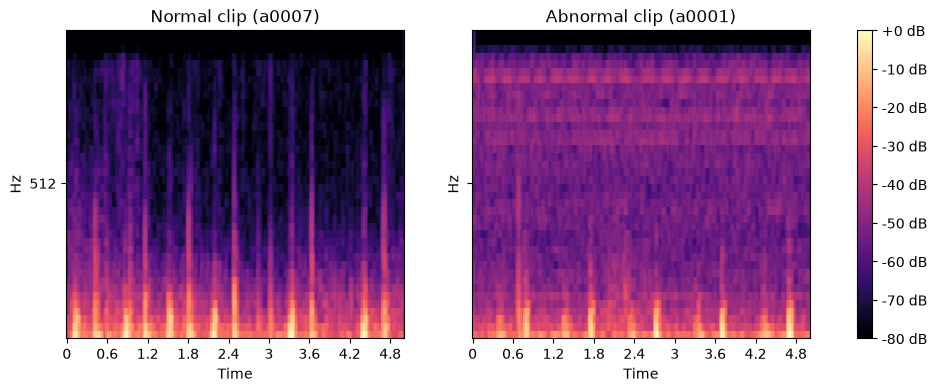

In [8]:
from src.preprocessing import (load_audio, middle_clip, to_melspec, scale_spec, make_clips,
                               recording_to_array, extract_features, SR, CLIP_SECONDS, INPUT_SHAPE)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, row) in zip(axes, [("Normal", normal_row), ("Abnormal", abnormal_row)]):
    clip = middle_clip(load_audio(row["path"]))
    S = to_melspec(clip)
    img = librosa.display.specshow(S, sr=SR, hop_length=40, x_axis="time", y_axis="mel", fmin=20, fmax=1000, ax=ax)
    ax.set_title(f"{name} clip ({row['record']})")
    print(f"{name}: clip samples = {len(clip)} | spectrogram shape (mel bands, time steps) = {S.shape}")
fig.colorbar(img, ax=axes, format="%+2.0f dB")
plt.show()

**What the output shows (real data):**
- **Shape = (40, 251):** each 5 s clip becomes an image 40 pixels tall (frequency bands) and 251 pixels wide (time steps). This is the CNN's input size.
- **Bright vertical stripes** are the heart sounds, repeating about every 0.6 to 0.9 s, matching the spikes in the waveform.
- **Most energy sits at low frequencies** (the bright band at the bottom): heart sounds are low-pitched.
- **In this one pair**, the normal clip has clean beats and a dark, quiet background; the abnormal clip has weaker beats and a noisier, grainier background.

**Careful:** that is one clip per class. The extra noise could just be a noisier recording and not a heart problem. We need many recordings and a properly tested model before concluding anything.

### Step 7c. Does the band-pass filter clean up a noisy recording?

**What this cell does:** takes one recording flagged as **poor quality** and shows its spectrogram **before** (raw) and **after** the band-pass filter.

**Why:** one of the lessons from Formative 2 was to check what noisy audio does and then **re-test on new recordings** after fixing it. Here we only *look* at the effect. The real re-test is the final evaluation on the held-out test recordings, which the filter and the model never saw while being built.

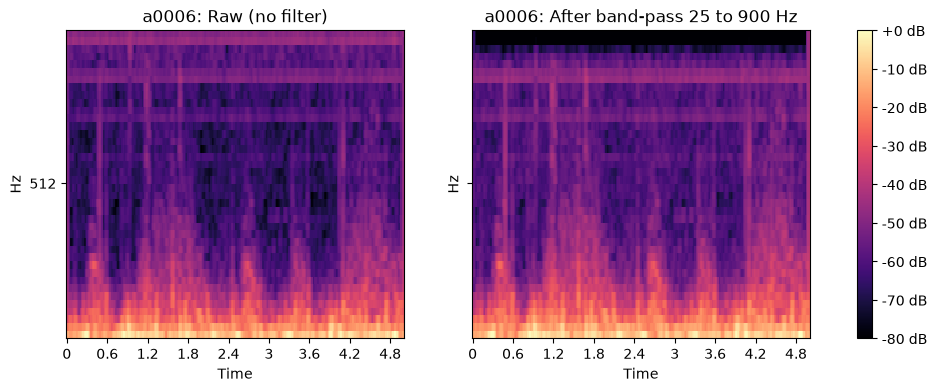

In [9]:
bad = df[df["quality"] == 0].iloc[0]
raw = middle_clip(load_audio(bad["path"], bandpass=False))
clean = middle_clip(load_audio(bad["path"], bandpass=True))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, sig) in zip(axes, [("Raw (no filter)", raw), ("After band-pass 25 to 900 Hz", clean)]):
    img = librosa.display.specshow(to_melspec(sig), sr=SR, hop_length=40, x_axis="time", y_axis="mel", fmin=20, fmax=1000, ax=ax)
    ax.set_title(f"{bad['record']}: {name}")
fig.colorbar(img, ax=axes, format="%+2.0f dB")
plt.show()

**What changed in recording a0006 (flagged as poor quality)**

- **The top rows turned dark after filtering.** Everything above about 900 Hz is cut off by the band-pass filter, so the top of the right panel falls to about -80 dB (black). The hiss at the highest frequencies is gone.

- **The heart-sound pattern is the same in both panels.** The vertical stripes (the beats, roughly every 0.6 s) and the bright energy at the bottom (low frequencies) look almost identical before and after, so the filter did not damage the part of the signal that carries the heart sounds.

- **The noise bands in the middle did not go away.** The horizontal bright stripes across the middle of the spectrogram are in both panels. They sit inside the 25 to 900 Hz range that the filter keeps, so a band-pass filter cannot remove them. This is likely steady background noise or hum from the recording setup, which is why this recording is still poor quality after filtering.

- **Conclusion:** the filter cleans the edges (very high frequencies, and the very low rumble below 25 Hz that is hard to see here) and leaves the heart-sound band untouched, but it cannot fix noise that overlaps the heart-sound frequencies. This is why poor-quality recordings stay harder for the model (Step 17: AUC 0.90 vs 0.94 and more false alarms), and why the app shows quality warnings.

- **This is a visual check on one recording, not a test.** The real re-test after the noise handling is the evaluation on the held-out test recordings in Step 17, which the filter design and the model never saw.

## Step 8. Split the recordings into train / validation / test

**What this cell does:** splits the 3,240 recordings **by recording** into
- **train (70%)**: the model learns from these,
- **validation (15%)**: used to compare models and choose the decision threshold,
- **test (15%)**: locked away and used **once** at the very end to report performance.

The split is **stratified by source and label**: every source and both classes appear in each group in the same proportion. We ignore PhysioNet's own `validation` folder (it duplicates training recordings).

**Why now:** from here on, every exploration step uses the **training set only**, so the test recordings can never influence a decision (feedback point 1 from Formative 2).

In [10]:
from sklearn.model_selection import train_test_split

df["strata"] = df["source"] + "_" + df["abnormal"].astype(str)
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["strata"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["strata"], random_state=SEED)

df["split"] = ""
df.loc[train_df.index, "split"] = "train"
df.loc[val_df.index, "split"] = "val"
df.loc[test_df.index, "split"] = "test"

print("Recordings per split:\n", df["split"].value_counts().to_string())
print("\nAbnormal rate per split:\n", df.groupby("split")["abnormal"].mean().round(3).to_string())
print("\nRecordings per source and split:")
print(pd.crosstab(df["source"], df["split"])[["train", "val", "test"]])

df.to_csv("data/split_assignments.csv", index=False)

Recordings per split:
 split
train    2268
val       486
test      486

Abnormal rate per split:
 split
test     0.204
train    0.205
val      0.206

Recordings per source and split:
split   train  val  test
source                  
a         286   61    62
b         343   74    73
c          22    4     5
d          39    8     8
e        1498  322   321
f          80   17    17


**What the output shows (real data):**
- **Sizes:** 2,268 train (70%), 486 validation (15%), 486 test (15%).
- **Abnormal rate is almost identical** in all three splits (0.204, 0.205, 0.206), so each split is representative.
- **Every source appears in every split in about 70/15/15.** Source `e` dominates (1,498 training recordings), while sources `c` and `d` are tiny: source `c` has only 4 validation and 5 test recordings.

**What this means:** overall results will mostly reflect source `e`, so we also report **per-source** results. For `c` and `d` those numbers are very uncertain (a handful of recordings can swing the score).
**Limitation:** the dataset has no patient IDs, so the same patient may appear in more than one recording across splits. That could make scores slightly optimistic, and it is stated in the README.

## Step 9. Average spectrograms: normal vs abnormal (training data only)

**What this cell does:** for sources `a` and `e` separately, takes up to 100 good-quality **training** recordings per class, cuts the middle 5 s of each, converts them to spectrograms and **averages** them. It plots the average normal, the average abnormal and the **difference** (abnormal minus normal).

**Why**
- One example per class proves nothing; an average over many recordings shows the *typical* pattern.
- Beats fall at different moments in each recording, so averaging blurs the vertical stripes. What is left is the typical **frequency profile**.
- Comparing **inside one source** removes differences caused by equipment or hospital.
- Training data and good quality only: no validation or test recordings are touched.

source a | normal | recordings averaged: 81
source a | abnormal | recordings averaged: 100
source e | normal | recordings averaged: 100
source e | abnormal | recordings averaged: 100


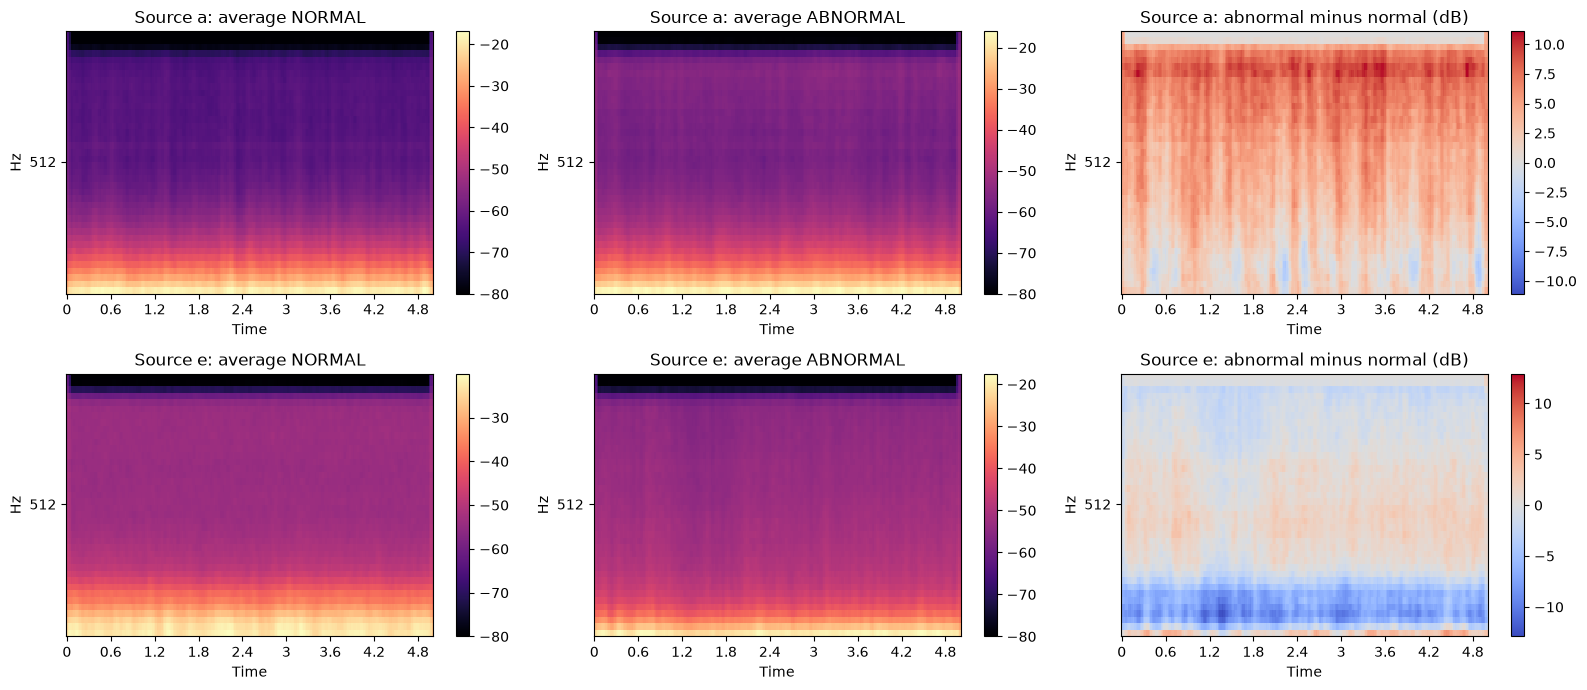

In [11]:
train_good = df[(df["split"] == "train") & (df["quality"] == 1)]
averages = {}
fig, axes = plt.subplots(2, 3, figsize=(16, 7))

for row, src in enumerate(["a", "e"]):
    for flag in [0, 1]:
        sub = train_good[(train_good["source"] == src) & (train_good["abnormal"] == flag)]
        sub = sub.sample(min(100, len(sub)), random_state=SEED)
        specs = [to_melspec(middle_clip(load_audio(p))) for p in sub["path"]]
        averages[(src, flag)] = np.mean(specs, axis=0)
        print(f"source {src} | {'abnormal' if flag else 'normal'} | recordings averaged: {len(sub)}")

    normal_avg, abnormal_avg = averages[(src, 0)], averages[(src, 1)]
    diff = abnormal_avg - normal_avg
    lim = np.abs(diff).max()
    for col, (data, title, cmap, kw) in enumerate([
            (normal_avg, f"Source {src}: average NORMAL", "magma", {}),
            (abnormal_avg, f"Source {src}: average ABNORMAL", "magma", {}),
            (diff, f"Source {src}: abnormal minus normal (dB)", "coolwarm", {"vmin": -lim, "vmax": lim})]):
        img = librosa.display.specshow(data, sr=SR, hop_length=40, x_axis="time", y_axis="mel",
                                       fmin=20, fmax=1000, cmap=cmap, ax=axes[row, col], **kw)
        axes[row, col].set_title(title)
        fig.colorbar(img, ax=axes[row, col])
plt.tight_layout()
plt.show()

**What the output shows (real data; right column: red = abnormal has more energy, blue = less):**
- Source `a` normal had only 81 good-quality training recordings; the other groups used 100.
- **Both classes:** most energy is at low frequencies (the bright band at the bottom).
- **Source `a`:** abnormal recordings have **more energy at mid and high frequencies** (red, about +5 to +10 dB) and about the same at the lowest frequencies.
- **Source `e`:** abnormal recordings have **less energy in the low-frequency band** (strong blue, about -10 dB) and slightly more at higher frequencies (faint red).
- **Where they agree:** in both sources abnormal recordings have a **flatter spectrum**, relatively more energy at mid/high frequencies compared with the low-frequency peak, which is consistent with murmurs adding sound between and around the main heart sounds.
- **Where they disagree:** the size and shape of the difference differ between `a` and `e`. The pattern depends on the source, a warning that a model could partly learn the recording setup.

**Cautions:** each spectrogram is scaled to its own loudest point, so "less low-frequency energy" and "more high-frequency energy" are linked. Abnormal recordings may simply be noisier, a recording effect and not a heart effect. These are averages: individual recordings overlap a lot, so classification will not be easy.

## Step 10. Turn the patterns into numbers: feature insights

**What this cell does:** computes five interpretable numbers for **every** recording (so the UI can show them) and saves them in `data/features.csv`, then analyses **training recordings only**:
- `low_share`: share of the sound energy at 20 to 150 Hz,
- `mid_share`: 150 to 400 Hz,
- `high_share`: 400 to 1000 Hz,
- `spectral_centroid_hz`: the "centre of mass" of the spectrum (higher = brighter, higher-pitched sound),
- `spectral_flatness`: close to 1 for noise-like sound, close to 0 for tonal / peaky sound.

It then (1) draws boxplots of three features for normal vs abnormal **inside sources `a` and `e`**, and (2) measures how well **each feature alone predicts the label** with a one-feature **AUC** (0.5 = no information; 1.0 or 0.0 = perfect).

**Why this way:** the link between a feature and the target is shown directly against the label, not with a heatmap of features against each other (that cannot show a link to the target). All volume is removed before computing the features, so loudness is not a clue.

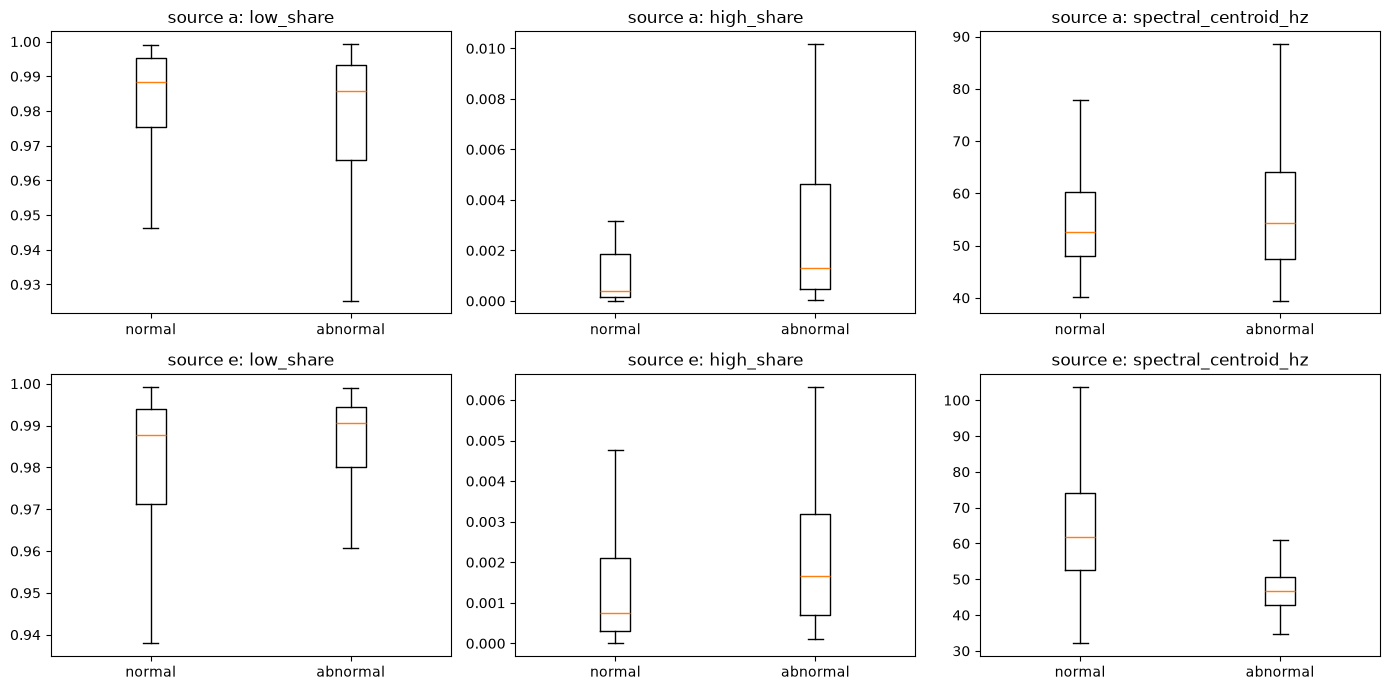

group,all training,source a,source b,source e
feature,,,,
high_share,0.59,0.65,0.53,0.65
low_share,0.50,0.43,0.51,0.57
mid_share,0.49,0.55,0.49,0.41
spectral_centroid_hz,0.37,0.52,0.48,0.16
spectral_flatness,0.59,0.66,0.51,0.62


In [12]:
from sklearn.metrics import roc_auc_score

feat_rows = [extract_features(load_audio(p)) for p in df["path"]]
feats = pd.concat([df[["record", "source", "abnormal", "quality", "split", "duration"]].reset_index(drop=True),
                   pd.DataFrame(feat_rows)], axis=1)
feats.to_csv("data/features.csv", index=False)

FEATURES = ["low_share", "mid_share", "high_share", "spectral_centroid_hz", "spectral_flatness"]
train_feats = feats[feats["split"] == "train"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for r, src in enumerate(["a", "e"]):
    sub = train_feats[train_feats["source"] == src]
    for c, f in enumerate(["low_share", "high_share", "spectral_centroid_hz"]):
        axes[r, c].boxplot([sub[sub["abnormal"] == k][f] for k in [0, 1]], showfliers=False)
        axes[r, c].set_xticklabels(["normal", "abnormal"])
        axes[r, c].set_title(f"source {src}: {f}")
plt.tight_layout()
plt.show()

groups = [("all training", train_feats)] + [
    (f"source {s}", train_feats[train_feats["source"] == s]) for s in SOURCES
    if (train_feats["source"] == s).sum() >= 100 and train_feats[train_feats["source"] == s]["abnormal"].nunique() == 2]
rows = []
for name, sub in groups:
    for f in FEATURES:
        rows.append({"group": name, "feature": f, "AUC vs target": roc_auc_score(sub["abnormal"], sub[f])})
auc_table = pd.DataFrame(rows).pivot(index="feature", columns="group", values="AUC vs target").round(2)
auc_table

**How to read the table:** each number is the AUC of one feature used alone against the label. 0.50 means no information, above 0.5 means abnormal recordings have *higher* values, below 0.5 means abnormal recordings have *lower* values.

| Feature | All training | Source a | Source b | Source e |
|---|---|---|---|---|
| high_share | 0.59 | 0.65 | 0.53 | 0.65 |
| low_share | 0.50 | 0.43 | 0.51 | 0.57 |
| mid_share | 0.49 | 0.55 | 0.49 | 0.41 |
| spectral_centroid_hz | 0.37 | 0.52 | 0.48 | 0.16 |
| spectral_flatness | 0.59 | 0.66 | 0.51 | 0.62 |

**1. High-frequency share (400 to 1000 Hz): the most consistent feature, but weak**

- **What it measures:** the fraction of the sound energy that sits at high frequencies.

- **Direction:** abnormal is higher. In the boxplots the abnormal median is higher than the normal one in both sources (source a about 0.0013 vs 0.0004, source e about 0.0017 vs 0.0008), and the abnormal boxes reach much higher.

- **Strength:** weak (AUC 0.59 overall, 0.53 to 0.65 by source), and the boxes overlap a lot.

- **Across sources:** it points the same way in all three sources (every AUC is above 0.5), so it is the most trustworthy of the features.

- **Link to murmurs:** a murmur is extra sound between the main heart sounds, which moves some energy from the low-frequency heart sounds towards higher frequencies. That fits the direction. Caution: this band holds only about 0.1% of the energy, and noise also adds high-frequency energy, so it is not proof of a murmur.

**2. Low-frequency share (20 to 150 Hz): unreliable**

- **What it measures:** the fraction of energy in the low band where the normal heart sounds (S1 and S2) sit. It is about 0.99 for nearly every recording, so there is little room to differ.

- **Direction:** it flips. AUC is 0.43 in source a (abnormal lower), 0.51 in b (nothing) and 0.57 in e (abnormal higher), and 0.50 overall.

- **Strength:** none overall. The boxes overlap almost completely.

- **Meaning:** it depends on the source, so by itself it cannot be used, and a model that relied on it would be learning the recording setup.

**3. Spectral centroid (the "centre of mass" of the spectrum): depends strongly on the source**

- **What it measures:** the average frequency of the sound, weighted by energy. Higher means a brighter, higher-pitched sound. Values are low here (about 40 to 100 Hz) because most energy is in the lowest band.

- **Direction:** source a and source b show almost nothing (AUC 0.52 and 0.48, boxes overlap heavily). In source e it is *reversed* and strong (AUC 0.16: abnormal recordings have a *lower* centroid, about 47 Hz vs 62 Hz). The pooled value (0.37) comes mostly from that one source.

- **Meaning:** a lower centroid for abnormal recordings is the opposite of the murmur idea. It is more likely caused by how source e was recorded (device, position, patients) than by the heart. This is a shortcut risk: a feature that is strong in one source and absent in the others.

**4. Spectral flatness (extra):** abnormal is higher (0.59 overall, 0.51 to 0.66 by source), meaning abnormal recordings are slightly more noise-like and less tonal. Consistent direction, weak strength.

**Overall conclusion:**

- No single feature is strong across all sources. The best consistent ones (high_share, spectral_flatness) reach only AUC 0.6 to 0.66, which is weak.

- The only strong value (centroid in source e, AUC 0.16) does not hold in the other sources.

- This matches the plan of using the whole spectrogram (CNN) rather than a few hand-picked numbers, and it supports the per-source checks in Step 17, because source differences can look like heart differences.

- The mid_share row is a reminder that "closer to 0.5" means "no information": it is 0.49 overall but 0.55 in a and 0.41 in e, so it also changes direction by source.

## Step 11. Build the model inputs (clip arrays)

**What this cell does:** for every recording in each split it runs the full preprocessing pipeline and stacks the clips into arrays:
- `X_*`: spectrogram clips, shape (number of clips, 40, 251, 1),
- `y_*`: 1 if the clip's recording is abnormal, 0 if normal,
- `rec_*`: which recording each clip came from (needed to average clip predictions per recording later).

Training uses up to **3 clips per recording** so long recordings do not dominate; validation and test use up to 5, so each recording-level prediction is based on more of the recording.

**Why:** poor-quality recordings are **kept** in all splits. Real recordings are noisy, so the model must cope with noise; later we report results for good and poor quality separately.

In [13]:
def build_arrays(frame, max_clips):
    X_list, y_list, rec_list = [], [], []
    for idx, row in frame.iterrows():
        arr = recording_to_array(row["path"], max_clips=max_clips)
        X_list.append(arr)
        y_list.append(np.full(len(arr), row["abnormal"]))
        rec_list.append(np.full(len(arr), idx))
    return np.concatenate(X_list), np.concatenate(y_list).astype("float32"), np.concatenate(rec_list)

X_tr, y_tr, rec_tr = build_arrays(df[df["split"] == "train"], max_clips=3)
X_val, y_val, rec_val = build_arrays(df[df["split"] == "val"], max_clips=5)
X_te, y_te, rec_te = build_arrays(df[df["split"] == "test"], max_clips=5)

for name, X, y in [("train", X_tr, y_tr), ("validation", X_val, y_val), ("test", X_te, y_te)]:
    print(f"{name:10s} X {X.shape} | abnormal clips {y.mean():.1%} | {X.nbytes / 1e6:.0f} MB")

train      X (5709, 40, 251, 1) | abnormal clips 20.9% | 229 MB
validation X (1639, 40, 251, 1) | abnormal clips 22.1% | 66 MB
test       X (1677, 40, 251, 1) | abnormal clips 22.2% | 67 MB


**Shapes and sizes**

| Split | Recordings | Clips | Array shape | Abnormal clips | Memory |
|---|---|---|---|---|---|
| Train | 2268 | 5,709 | (5709, 40, 251, 1) | 20.9% | 229 MB |
| Validation | 486 | 1,639 | (1639, 40, 251, 1) | 22.1% | 66 MB |
| Test | 486 | 1,677 | (1677, 40, 251, 1) | 22.2% | 67 MB |

- **(a) The last three numbers are the same in every split:** 40 mel bands × 251 time steps × 1 channel. Each clip is one 5-second spectrogram, so the same model can read all three splits. The first number is just the number of clips.

- **(b) The abnormal share of clips is about 21 to 22%,** close to the 20.5% abnormal share of recordings. It is slightly higher because abnormal recordings tend to be longer and so give more clips. All three splits have almost the same share, so they are comparable.

- **(c) Memory is small:** about 362 MB in total (float32), which fits easily in the RAM of a normal PC.

- **Clips per recording:** training averages about 2.5 clips per recording (cap of 3) and validation and test about 3.4 (cap of 5). Training has about 5,700 clips even though far more are possible from the long recordings (13,015 in total): the cap stops long recordings from dominating, and it keeps the training time short. Validation and test use more clips per recording so each recording-level prediction is based on more of the recording.

- **Clips are not independent.** Clips from one recording are neighbours, which is why the split was done by *recording* in Step 8 and why predictions are averaged per recording (recording IDs in `rec_*` make that possible). Splitting by clip would leak the same recording into train and test.

## Step 12. The model module (`src/model.py`)

**What this cell does:** saves `src/model.py`, used by the notebook, the API and the retraining code.

**What is inside**
- `build_cnn`: a small **CNN** (convolutional neural network): three blocks of *convolution, batch normalisation, ReLU, max-pooling*, then global average pooling and two dense layers ending in one sigmoid output = **probability that the recording is abnormal**.
- **Optimization techniques** available as switches: **batch normalisation**, **dropout**, **L2 weight penalty**, **class weights** (the rare abnormal class counts more), **SpecAugment-style augmentation** (random time shift, time mask and frequency mask), **early stopping** and **learning-rate reduction** on plateau, and **threshold selection on validation data**.
- `evaluate_binary`: accuracy, precision, recall (sensitivity), specificity, F1, ROC-AUC, PR-AUC and the confusion matrix.
- `aggregate_by_recording`: averages the clip probabilities of one recording into a single probability.
- `choose_threshold`: picks the decision threshold on validation data so that at least 85% of abnormal recordings are caught, with as few false alarms as possible.
- `fine_tune`: **retraining**. Continues training a saved model on new data mixed with a sample of old data, using a smaller learning rate.
- `save_model` / `load_model`: the model is saved to a temporary file and then renamed, so a running API never reads a half-written file.

In [ ]:
%%writefile src/model.py
"""CNN model, training, evaluation and fine-tuning for heart-sound classification.

Labels: 0 = normal, 1 = abnormal. The model outputs the probability of "abnormal".
"""
import json
import os

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)

from .preprocessing import INPUT_SHAPE, N_FRAMES, N_MELS

SEED = 42


# model
def compile_model(model, lr=1e-3):
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="auc"),
                 keras.metrics.Recall(name="recall"),
                 keras.metrics.Precision(name="precision")],
    )
    return model


def build_cnn(input_shape=INPUT_SHAPE, filters=(16, 32, 64), dropout=0.3, l2=1e-4,
              use_bn=True, lr=1e-3):
    """Small CNN: 3 x (Conv -> [BatchNorm] -> ReLU -> MaxPool) -> pooling -> dense -> sigmoid.

    use_bn=False, dropout=0, l2=0 gives the plain version; the defaults give the optimized one.
    """
    reg = regularizers.l2(l2) if l2 else None
    inputs = keras.Input(shape=input_shape)
    x = inputs
    for f in filters:
        x = layers.Conv2D(f, 3, padding="same", kernel_regularizer=reg)(x)
        if use_bn:
            x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    if dropout:
        x = layers.Dropout(dropout)(x)
    x = layers.Dense(32, activation="relu", kernel_regularizer=reg)(x)
    if dropout:
        x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return compile_model(keras.Model(inputs, outputs), lr)


def save_model(model, path):
    """Save atomically (write a temp file, then rename) so a running API never reads half a file."""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    tmp = path.replace(".keras", ".tmp.keras")
    model.save(tmp)
    os.replace(tmp, path)


def load_model(path, compile_for_training=False, lr=1e-3):
    model = keras.models.load_model(path, compile=False)
    if compile_for_training:
        compile_model(model, lr)
    return model


# augmentation
def _mask(x, length, max_width, axis):
    """Zero out a random band along one axis (SpecAugment-style)."""
    width = tf.random.uniform([], 0, max_width + 1, dtype=tf.int32)
    start = tf.random.uniform([], 0, tf.maximum(length - width, 1), dtype=tf.int32)
    idx = tf.range(length)
    keep = tf.cast(tf.logical_not(tf.logical_and(idx >= start, idx < start + width)), x.dtype)
    shape = [1, 1, 1]
    shape[axis] = length
    return x * tf.reshape(keep, shape)


def spec_augment(x, y):
    """Random time shift + one time mask + one frequency mask on a (40, 251, 1) spectrogram."""
    shift = tf.random.uniform([], -25, 26, dtype=tf.int32)
    x = tf.roll(x, shift, axis=1)
    x = _mask(x, N_FRAMES, 20, axis=1)
    x = _mask(x, N_MELS, 4, axis=0)
    return x, y


def make_dataset(X, y, batch_size=32, augment=False, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X.astype("float32"), np.asarray(y, dtype="float32")))
    if shuffle:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    if augment:
        ds = ds.map(spec_augment, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


# training
def compute_class_weights(y):
    """Give the rare class (abnormal) a larger weight so the model does not ignore it."""
    y = np.asarray(y)
    n, n1 = len(y), int(y.sum())
    n0 = n - n1
    return {0: n / (2.0 * max(n0, 1)), 1: n / (2.0 * max(n1, 1))}


def train_model(model, X_train, y_train, X_val, y_val, epochs=30, batch_size=32,
                augment=True, use_class_weights=True, patience=6, verbose=2):
    """Train with early stopping on validation AUC and learning-rate reduction on plateau."""
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=patience,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.5,
                                          patience=max(2, patience // 2), min_lr=1e-6),
    ]
    history = model.fit(
        make_dataset(X_train, y_train, batch_size, augment=augment, shuffle=True),
        validation_data=make_dataset(X_val, y_val, batch_size),
        epochs=epochs, shuffle=False,   # shuffling is done inside make_dataset
        class_weight=compute_class_weights(y_train) if use_class_weights else None,
        callbacks=callbacks, verbose=verbose,
    )
    return history


def predict_clips(model, X, batch_size=64):
    """Probability of 'abnormal' for each clip."""
    return model.predict(X.astype("float32"), batch_size=batch_size, verbose=0).ravel()


def fine_tune(model, X_new, y_new, X_replay, y_replay, X_val, y_val,
              epochs=8, lr=1e-4, batch_size=32, replay_multiplier=3, seed=SEED, verbose=2):
    """Continue training a pretrained model on NEW data mixed with a sample of OLD data.

    Mixing in old ("replay") data stops the model forgetting what it learned before.
    A smaller learning rate keeps the update gentle.
    """
    rng = np.random.RandomState(seed)
    n_replay = min(len(X_replay), max(200, replay_multiplier * len(X_new)))
    pick = rng.choice(len(X_replay), n_replay, replace=False)
    X_mix = np.concatenate([X_new, X_replay[pick]]).astype("float32")
    y_mix = np.concatenate([y_new, y_replay[pick]]).astype("float32")
    compile_model(model, lr)
    history = train_model(model, X_mix, y_mix, X_val, y_val, epochs=epochs,
                          batch_size=batch_size, patience=3, verbose=verbose)
    return model, history


# evaluation
def aggregate_by_recording(rec_ids, probs, labels):
    """Average the clip probabilities of each recording -> one probability per recording."""
    frame = pd.DataFrame({"rec": rec_ids, "p": probs, "y": labels})
    grouped = frame.groupby("rec").agg(p=("p", "mean"), y=("y", "first"))
    return grouped.index.to_numpy(), grouped["p"].to_numpy(), grouped["y"].to_numpy().astype(int)


def evaluate_binary(y_true, y_prob, threshold=0.5):
    """Accuracy, precision, recall (sensitivity), specificity, F1, ROC-AUC, PR-AUC and the confusion matrix."""
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob)
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    both = len(np.unique(y_true)) == 2
    return {
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "specificity": float(tn / (tn + fp)) if (tn + fp) else float("nan"),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, y_prob)) if both else float("nan"),
        "pr_auc": float(average_precision_score(y_true, y_prob)) if both else float("nan"),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


def choose_threshold(y_true, y_prob, min_recall=0.85):
    """Pick the decision threshold on VALIDATION data.

    Among thresholds that catch at least `min_recall` of the abnormal recordings,
    take the one with the fewest false alarms. If none reaches it, use the best-F1 threshold.
    """
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob)
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    ok = np.where(tpr >= min_recall)[0]
    if len(ok):
        t = float(thr[ok[0]])
        return min(t, 1.0)
    candidates = np.linspace(0.05, 0.95, 91)
    scores = [f1_score(y_true, (y_prob >= c).astype(int), zero_division=0) for c in candidates]
    return float(candidates[int(np.argmax(scores))])


def load_json(path, default=None):
    try:
        with open(path) as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return default


def save_json(obj, path):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2)
    os.replace(tmp, path)

Overwriting src/model.py


**Reading the output:** `Writing src/model.py`. Two ideas worth understanding before moving on:
- **Why average clips per recording?** A recording is cut into several 5 s clips. One clip may be noisy; the average over the clips is more stable, and the diagnosis is for the whole recording.
- **Why mix old data into retraining?** If we fine-tuned only on new recordings, the model could "forget" what it learned before (catastrophic forgetting). Replaying some old data prevents that.

### Step 12b. The two CNN versions we will compare

**What this cell does:** imports the functions and builds two models with the same layers: a **plain CNN** (no batch norm, no dropout, no weight penalty) and the **optimized CNN** (batch norm, dropout 0.3, L2 1e-4). It prints the architecture of the optimized one and the class weights.

**Why:** to show the effect of the optimization techniques, we train both and compare them on the validation set.

In [15]:
from src.model import (build_cnn, train_model, predict_clips, aggregate_by_recording, evaluate_binary,
                       choose_threshold, fine_tune, save_model, load_model, save_json, compute_class_weights)

plain = build_cnn(dropout=0, l2=0, use_bn=False)
optimized = build_cnn()
print("Plain CNN parameters:", plain.count_params(), "| Optimized CNN parameters:", optimized.count_params())
optimized.summary()
print("Class weights (normal, abnormal):", {k: round(v, 2) for k, v in compute_class_weights(y_tr).items()})

Plain CNN parameters: 25409 | Optimized CNN parameters: 25857


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 40, 251, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 40, 251, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 40, 251, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 40, 251, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 20, 125, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 20, 125, 32)    │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 20, 125, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 20, 125, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 10, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 10, 62, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 10, 62, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 10, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 31, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,857 (101.00 KB)

 Trainable params: 25,633 (100.13 KB)

 Non-trainable params: 224 (896.00 B)

Class weights (normal, abnormal): {0: 0.63, 1: 2.39}


**What the printout shows**

- **Input shape `(None, 40, 251, 1)`:** `None` is the batch size (any number of clips at once), then 40 mel bands × 251 time steps × 1 channel, the same shape as the arrays from Step 11. The output is one number between 0 and 1 (`(None, 1)`): the probability that the clip is abnormal.

- **Size:** the optimized CNN has **25,857 parameters (about 101 KB)**; the plain CNN has 25,409. That is a few tens of thousands, a very small model: fast to train on a normal PC without a GPU, and light enough to deploy (the saved file is 0.39 MB).

- **Where the parameters are:**

| Part | Parameters |
|---|---|
| 3 convolution layers (16, 32, 64 filters) | 23,296 (160 + 4,640 + 18,496) |
| Dense layers (32 units, then 1 output) | 2,113 (2,080 + 33) |
| Batch normalization (3 layers) | 448 |
| **Total** | **25,857** |

- **Difference between the two models:** the optimized version adds only the 448 batch-normalization parameters (25,409 → 25,857), plus dropout, which has no parameters. It is the same size, so any difference in results comes from the training method (BatchNorm, dropout, L2, class weights, augmentation, early stopping), not from a bigger model.

- **Trainable vs non-trainable:** 25,633 are trainable. The 224 non-trainable ones are the running averages that BatchNorm keeps (mean and variance for 112 channels); they are updated during training but not by gradient descent.

- **Design:** the three blocks (convolution, BatchNorm, ReLU, max-pooling) shrink the 40×251 spectrogram to 5×31 while the number of filters grows (16 → 32 → 64). Global average pooling then reduces each filter to one number, which keeps the model small and makes it less likely to memorise exact positions in time.

- **Class weights `{0: 0.63, 1: 2.39}`:** the abnormal class gets a weight of about 2.4 versus 0.63 for normal, a ratio of about 3.8, because abnormal clips are only about 21% of the training clips. During training a mistake on an abnormal clip counts about four times as much as one on a normal clip, so the model cannot score well by predicting "normal" for everything (the majority baseline in Step 13 shows how tempting that is).

## Step 13. Baselines: how well do simple models do?

**What this cell does:** builds three reference models and scores them on the **validation** set (not the test set):
- **Majority baseline:** always predicts the more common class. This is the "do nothing clever" score.
- **Logistic regression** and **Random forest** from scikit-learn, using 80 simple numbers per clip: the **average and the standard deviation over time of each of the 40 frequency bands**.

The scaler is **fitted on training data only**, then applied to validation data. Clip probabilities are averaged per recording, so every model is scored on recordings.

**Why:** a CNN is only worth its complexity if it beats simple models. These also act as a sanity check on the data.

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

def band_stats(X):
    S = X[..., 0]                                            # (clips, 40 bands, 251 time steps)
    return np.concatenate([S.mean(axis=2), S.std(axis=2)], axis=1)     # 80 numbers per clip

F_tr, F_val = band_stats(X_tr), band_stats(X_val)
scaler = StandardScaler().fit(F_tr)                          # fitted on TRAIN only
models = {
    "Majority baseline": DummyClassifier(strategy="prior"),
    "Logistic regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=SEED),
}
baseline_results = {}
for name, clf in models.items():
    clf.fit(scaler.transform(F_tr), y_tr)
    p_clip = clf.predict_proba(scaler.transform(F_val))[:, 1]
    _, p_rec, y_rec = aggregate_by_recording(rec_val, p_clip, y_val)
    baseline_results[name] = evaluate_binary(y_rec, p_rec, 0.5)

COLS = ["roc_auc", "recall", "specificity", "precision", "f1", "accuracy"]
pd.DataFrame(baseline_results).T[COLS].round(3)

,roc_auc,recall,specificity,precision,f1,accuracy
Majority baseline,0.500,0.00,1.000,0.000,0.000,0.794
Logistic regression,0.900,0.87,0.790,0.518,0.649,0.807
Random forest,0.961,0.85,0.915,0.720,0.780,0.901


**How to read the table (validation set, recording level, threshold 0.5)**

| Model | ROC-AUC | Recall | Specificity | Precision | F1 | Accuracy |
|---|---|---|---|---|---|---|
| Majority baseline | 0.500 | 0.00 | 1.000 | 0.000 | 0.000 | 0.794 |
| Logistic regression | 0.900 | 0.87 | 0.790 | 0.518 | 0.649 | 0.807 |
| Random forest | 0.961 | 0.85 | 0.915 | 0.720 | 0.780 | 0.901 |

- **Majority baseline:** AUC 0.5 and recall 0, yet accuracy 0.794. Always answering "normal" looks "79% correct" because about 79% of recordings are normal, and it catches no abnormal recording. This is why accuracy alone is misleading here.

- **Logistic regression** reaches AUC 0.900 and recall 0.87, but only 0.79 specificity: it flags about 1 in 5 normal recordings, so its precision is just 0.518 (about half of its "abnormal" calls are false alarms). Its accuracy (0.807) is barely above the majority baseline (0.794), which again shows that recall and AUC are the numbers to watch.

- **Random forest is the better of the two real baselines**, by 0.061 in AUC (0.961 vs 0.900). At the same recall (0.85 vs 0.87) it makes far fewer false alarms: specificity 0.915 vs 0.790, precision 0.720 vs 0.518, F1 0.780 vs 0.649.

- **The benchmark for the CNN is therefore AUC 0.961.** The CNN (Step 15) must beat it, or at least match it for a good reason, to justify its extra complexity.

- **Fair comparison note:** these baselines use the default threshold 0.5 and no threshold tuning. AUC does not depend on the threshold, so AUC is the fairest number to compare across models. The CNN's chosen threshold (0.643) is set later in Step 16.

- **Sanity check on the data:** simple models on simple band statistics already reach AUC 0.90 to 0.96, so there is a real, learnable signal in the recordings. Some of it may come from the recording source rather than the heart; this is checked per source in Step 17.

## Step 14. Train the plain CNN

**What this cell does:** trains the plain CNN (no optimization tricks, no class weights, no augmentation) for up to 30 epochs with **early stopping** on validation AUC, then plots the loss and AUC curves.

**Key terms**
- **Epoch:** one pass over all training clips.
- **Loss:** how wrong the model's probabilities are (lower is better). **Overfitting** = training loss keeps falling while validation loss rises: the model memorises instead of learning.
- **Early stopping:** stop when validation AUC has not improved for a few epochs and go back to the best epoch.

**Why:** this is the reference to see whether the optimization techniques really help.

Epoch 1/30
179/179 - 18s - 98ms/step - auc: 0.5203 - loss: 0.5227 - precision: 0.2812 - recall: 0.0076 - val_auc: 0.5674 - val_loss: 0.5412 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/30
179/179 - 14s - 79ms/step - auc: 0.5622 - loss: 0.5087 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_auc: 0.6420 - val_loss: 0.5188 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/30
179/179 - 11s - 62ms/step - auc: 0.6828 - loss: 0.4806 - precision: 0.4286 - recall: 0.0025 - val_auc: 0.8268 - val_loss: 0.4858 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 4/30
179/179 - 9s - 48ms/step - auc: 0.8594 - loss: 0.3643 - precision: 0.5907 - recall: 0.1065 - val_auc: 0.9368 - val_loss: 0.3333 - val_precision: 0.8029 - val_recall: 0.4601 - learning_rate: 0.0010
Epoch 5/30
179/179 - 9s - 51ms/step - auc: 0.9040 - loss: 0.3087 - precision: 0.6435 - recall: 0.5117 - val_auc: 0.9385 - val_loss: 0

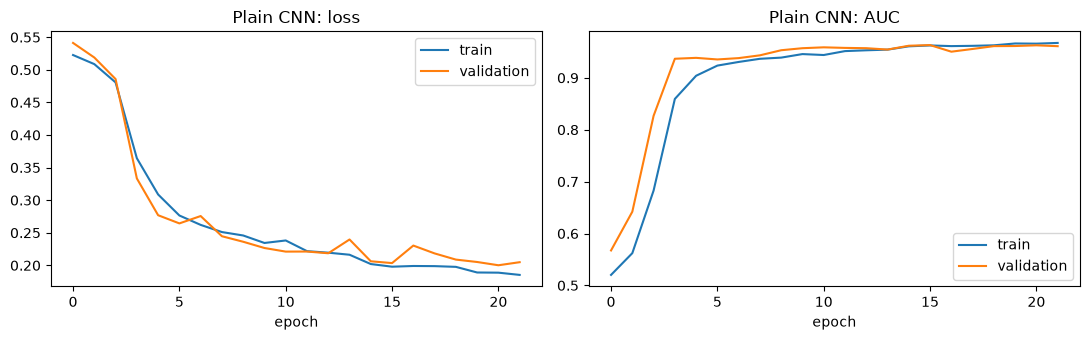

In [17]:
EPOCHS = int(os.environ.get("HEART_EPOCHS", "30"))

def plot_history(h, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(h.history["loss"], label="train"); axes[0].plot(h.history["val_loss"], label="validation")
    axes[0].set_title(f"{title}: loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(h.history["auc"], label="train"); axes[1].plot(h.history["val_auc"], label="validation")
    axes[1].set_title(f"{title}: AUC"); axes[1].set_xlabel("epoch"); axes[1].legend()
    plt.tight_layout(); plt.show()

tf.keras.utils.set_random_seed(SEED)
model_plain = build_cnn(dropout=0, l2=0, use_bn=False)
hist_plain = train_model(model_plain, X_tr, y_tr, X_val, y_val, epochs=EPOCHS,
                         augment=False, use_class_weights=False, verbose=2)
plot_history(hist_plain, "Plain CNN")

**What the output shows**

1. **Overfitting?** No clear overfitting. Training loss fell from 0.52 to 0.19 and validation loss from 0.54 to 0.20, and the two curves stay close the whole way. The final gap is small (train 0.185 vs validation 0.205), and the validation loss never trends upward. The validation curve is a bit jumpy (spikes at epochs 14 and 17). This is normal with a learning rate of 0.001 and a validation set of only 486 recordings, and it calms down after the learning rate is halved at epochs 15 and 20.

2. **Best epoch:** the highest validation AUC was **0.9631 at epoch 16**. Validation AUC did not beat that for the next 6 epochs (17 to 22), so early stopping ended training at epoch 22 and restored the weights from epoch 16. (Patience was 6 epochs, so 16 + 6 = 22.) This AUC is counted per clip, so it is not directly comparable with the per-recording AUC used in Step 16.

3. **Missing abnormal recordings:** without class weights the model starts by predicting "normal" for everything. In epochs 1 to 3 recall is about 0 and precision is 0, while AUC is still low. Once it learns the pattern (validation AUC jumps from 0.83 to 0.94 at epoch 4), recall at the default 0.5 threshold is still only about 0.67 at the best epoch (precision 0.84): roughly a third of abnormal clips are missed, because the model is cautious about the rare class. Step 16 confirms this at recording level: the plain CNN catches only 63 of 100 abnormal validation recordings at threshold 0.5.

**Takeaway:** the plain CNN learns steadily and does not overfit, but at the default threshold it under-detects abnormal sounds. This is the problem class weights and threshold tuning address in the next steps.

It is important to note that this is a score over all sources together. Sources differ a lot in size and abnormal rate, so a high overall AUC does not prove the model works inside each source. The per-source test in Step 17 checks that.

## Step 15. Train the optimized CNN

**What this cell does:** trains the optimized CNN with all techniques switched on: **batch normalisation, dropout, L2 penalty, class weights, SpecAugment augmentation, early stopping and learning-rate reduction**. Same data, same epochs.

**Why each technique**
- **Batch norm:** keeps the numbers inside the network on a stable scale, so training is faster and steadier.
- **Dropout / L2:** fight overfitting by making the network rely less on any single unit or large weight.
- **Class weights:** abnormal recordings are rarer, so errors on them count more.
- **Augmentation:** random shifts and masks create many variations of each clip, a cheap way to get more varied data and to be robust to noise.
- **Reduce learning rate on plateau:** smaller steps when improvement stalls.

Epoch 1/30
179/179 - 24s - 136ms/step - auc: 0.7077 - loss: 0.6384 - precision: 0.3213 - recall: 0.6862 - val_auc: 0.6805 - val_loss: 0.6612 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/30
179/179 - 21s - 119ms/step - auc: 0.8556 - loss: 0.4814 - precision: 0.4628 - recall: 0.8356 - val_auc: 0.8061 - val_loss: 1.0275 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/30
179/179 - 23s - 126ms/step - auc: 0.8808 - loss: 0.4316 - precision: 0.4936 - recall: 0.8758 - val_auc: 0.8703 - val_loss: 0.3685 - val_precision: 0.4901 - val_recall: 0.4766 - learning_rate: 0.0010
Epoch 4/30
179/179 - 30s - 168ms/step - auc: 0.8987 - loss: 0.3896 - precision: 0.5110 - recall: 0.9144 - val_auc: 0.8845 - val_loss: 0.4093 - val_precision: 0.5166 - val_recall: 0.7713 - learning_rate: 0.0010
Epoch 5/30
179/179 - 39s - 217ms/step - auc: 0.9064 - loss: 0.3734 - precision: 0.5122 - recall: 0.9304 - val_auc: 0.9106 - val_loss: 0.7358 - v

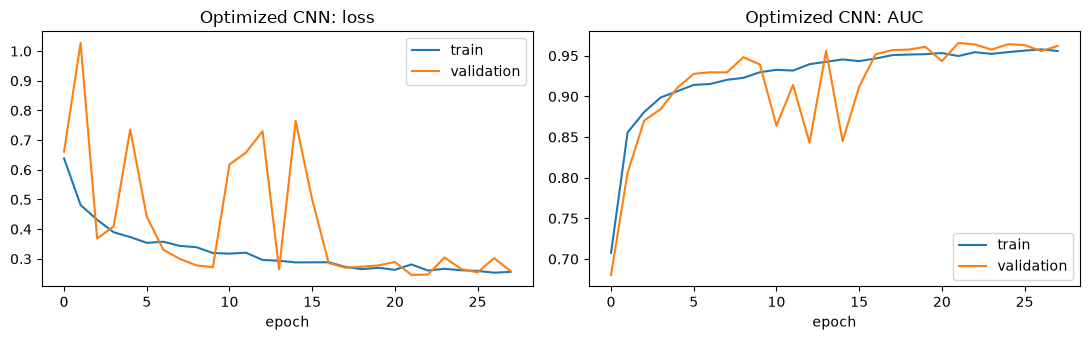

In [18]:
tf.keras.utils.set_random_seed(SEED)
model_opt = build_cnn()
hist_opt = train_model(model_opt, X_tr, y_tr, X_val, y_val, epochs=EPOCHS,
                       augment=True, use_class_weights=True, verbose=2)
plot_history(hist_opt, "Optimized CNN")

**What the output shows**

- **Best epoch:** the highest validation AUC was **0.9658 at epoch 22**. The next 6 epochs (23 to 28) did not beat it, so early stopping ended training at epoch 28 and restored the epoch-22 weights.

- **Compared with the plain CNN (Step 14, best 0.9631):** validation AUC is higher by only about 0.003. That is too small to call a real improvement, because validation has only 486 recordings. Compare them properly per recording in Step 16.

- **Train vs validation gap:** at the end the two curves sit together (train AUC about 0.955, validation about 0.96), so there is no overfitting. Training AUC is even a little *lower* than validation because dropout and augmentation make the training task harder on purpose. (The loss values here are weighted by class weights, so they cannot be compared with Step 14's loss.)

- **Unstable validation in epochs 2 to 16:** validation loss spikes (up to 1.03) and validation AUC drops to about 0.84 at epochs 11, 13 and 15. In those epochs validation recall is 1.0 with precision of only about 0.36, so the model was calling almost every clip abnormal. A likely cause is the high learning rate combined with batch normalisation and augmentation: the network's internal statistics during training differ from those at validation time. The curves become stable once the learning rate has been halved twice (from epoch 18). Early stopping and "restore best weights" protect us, because the saved model comes from a stable epoch.

- **Recall and precision at the default 0.5 threshold:** at the best epoch recall is about 0.99 and precision about 0.58. The opposite of Step 14 (recall about 0.67, precision about 0.84). Class weights make the model flag abnormal much more readily. This changes *where* the model operates, not necessarily how well it separates the classes.

**Takeaway:** the optimization techniques gave a more cautious, high-recall model, but at the clip level the ranking quality (AUC) barely moved. The fair test is in the next step, per recording and with the threshold chosen on validation data.

## Step 16. Compare everything on validation and choose the model and threshold

**What this cell does:**
1. Scores both CNNs on the **validation** recordings (clip probabilities averaged per recording) and puts them in one table with the baselines.
2. Picks the better CNN by **validation ROC-AUC** (a threshold-free measure).
3. Chooses the **decision threshold** on validation data: the lowest false-alarm rate that still catches at least **85% of abnormal recordings** (a screening tool should rarely miss a problem).

**Why validation, not test:** model choice and threshold are tuning decisions. If we made them on the test set, the test score would be optimistic (feedback point 1). The test set stays untouched until Step 17.

In [19]:
def score_recordings(model, X, y, rec, threshold=0.5):
    probs = predict_clips(model, X)
    ids, p, yy = aggregate_by_recording(rec, probs, y)
    return ids, p, yy, evaluate_binary(yy, p, threshold)

candidates = {"Plain CNN": model_plain, "Optimized CNN": model_opt}
cnn_val = {}
val_probs = {}
for name, m in candidates.items():
    ids, p, yy, met = score_recordings(m, X_val, y_val, rec_val, 0.5)
    cnn_val[name] = met
    val_probs[name] = (ids, p, yy)

print("Validation results at the default threshold 0.5:")
display(pd.DataFrame({**baseline_results, **cnn_val}).T[COLS].round(3))

best_name = max(cnn_val, key=lambda k: cnn_val[k]["roc_auc"])
best_model = candidates[best_name]
ids_val, p_val, y_val_rec = val_probs[best_name]
THRESHOLD = choose_threshold(y_val_rec, p_val, min_recall=0.85)
val_metrics = evaluate_binary(y_val_rec, p_val, THRESHOLD)

print(f"\nChosen model: {best_name} (validation AUC {cnn_val[best_name]['roc_auc']:.3f})")
print(f"Chosen threshold (from validation): {THRESHOLD:.3f}")
print("Validation metrics at that threshold:", {k: round(v, 3) for k, v in val_metrics.items() if k in COLS})

Validation results at the default threshold 0.5:


,roc_auc,recall,specificity,precision,f1,accuracy
Majority baseline,0.500,0.00,1.000,0.000,0.000,0.794
Logistic regression,0.900,0.87,0.790,0.518,0.649,0.807
Random forest,0.961,0.85,0.915,0.720,0.780,0.901
Plain CNN,0.946,0.63,0.966,0.829,0.716,0.897
Optimized CNN,0.947,1.00,0.738,0.498,0.664,0.792



Chosen model: Optimized CNN (validation AUC 0.947)
Chosen threshold (from validation): 0.643
Validation metrics at that threshold: {'accuracy': 0.858, 'precision': 0.612, 'recall': 0.85, 'specificity': 0.86, 'f1': 0.711, 'roc_auc': 0.947}


**What the output shows** (validation, 486 recordings: 100 abnormal, 386 normal; scored per recording)

| Model | ROC-AUC | Recall at 0.5 | Specificity at 0.5 |
|---|---|---|---|
| Majority baseline | 0.500 | 0.00 | 1.00 |
| Logistic regression | 0.900 | 0.87 | 0.79 |
| Random forest | 0.961 | 0.85 | 0.92 |
| Plain CNN | 0.946 | 0.63 | 0.97 |
| Optimized CNN | 0.947 | 1.00 | 0.74 |

- **CNN vs CNN:** the optimized CNN (AUC 0.947) and the plain CNN (0.946) are practically tied; the gap of 0.0015 is far below the noise level of a validation set with only 100 abnormal recordings. The optimization techniques did **not** improve how well the model separates the classes.

- **What the optimization did change is the operating point.** At the default threshold 0.5 the plain CNN is cautious (recall 0.63, specificity 0.97), while the class-weighted optimized CNN is eager (recall 1.00, specificity 0.74). Accuracy hides this: the plain CNN looks much better on accuracy (0.897 vs 0.792) yet misses 37 of the 100 abnormal recordings.

- **CNNs vs baselines:** both CNNs clearly beat logistic regression (0.947 vs 0.900) and the majority baseline. The **random forest has the highest AUC (0.961)**, slightly above the CNNs. With this little validation data the difference (about 0.014) is within noise, so the fair statement is that the random forest is **at least as good** as the CNN here, and at recall 0.85 it makes fewer false alarms (specificity 0.92 vs 0.86 for the tuned CNN, F1 0.78 vs 0.71).

- **Chosen model: Optimized CNN, a judgement call.** By the rule "highest validation AUC among the CNNs" the optimized one wins by a hair. We keep a CNN because (1) the retraining requirement is to continue training a saved model on new data, which a neural network does naturally while a random forest must be rebuilt from scratch; (2) the CNN reads the full time-frequency picture, while the random forest only sees 80 summary numbers per clip; (3) the differences are within noise. The comparison with the random forest is reported honestly rather than hidden.

- **Chosen threshold: 0.643**, picked on validation data only: the lowest false-alarm rate that still catches at least 85% of abnormal recordings. At this threshold the validation results are recall 0.85, specificity 0.86, precision 0.61, F1 0.71 (15 abnormal recordings missed, 54 normal ones flagged). This is a much better balance than the optimized CNN at 0.5 (F1 0.664, specificity 0.74).

**Takeaway:** on validation, a simple random forest is as good as the CNN. The CNN is kept for the retraining workflow and for its richer input. The next step shows how it behaves on unseen test recordings, including per source.

## Step 17. Final evaluation on the test set (used once)

**What this cell does:** scores the chosen model on the **test** recordings, using the threshold chosen in Step 16, and reports:
- **7 metrics**: accuracy, precision, recall, specificity, F1, ROC-AUC and PR-AUC,
- the **confusion matrix** and the **ROC curve**,
- results **per source** (a to f),
- results for **good-quality vs poor-quality** recordings.

**Why:** the test recordings were never used to train, tune or choose anything, so this is the honest estimate of how the model will do on new recordings. Per-source results show whether it works beyond the biggest source, and the quality split shows how noise hurts.

**Do not rerun this step to improve the score**, because that turns the test set into a tuning set.

TEST results (486 recordings, threshold 0.643):
accuracy       0.846
precision      0.583
recall         0.848
specificity    0.845
f1             0.691
roc_auc        0.936
pr_auc         0.776


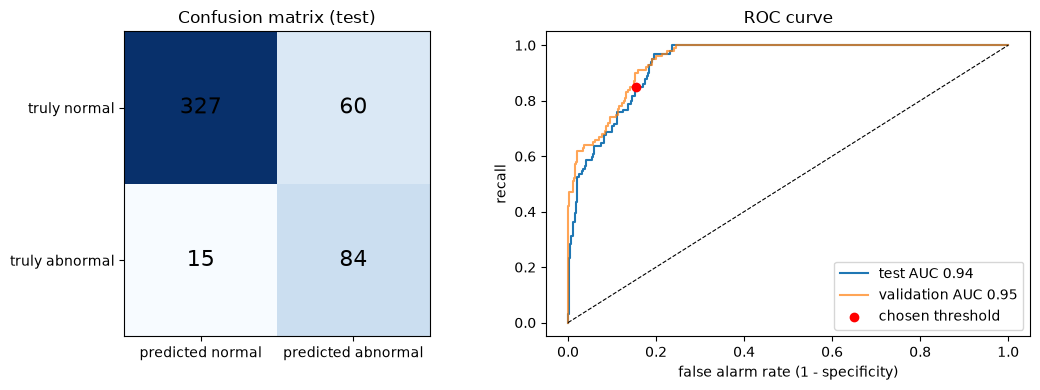


Per source (small sources are very uncertain):


,source,recordings,abnormal,roc_auc,recall,specificity
0,a,62,44,0.614,0.955,0.167
1,b,73,15,0.359,0.467,0.310
2,c,5,4,0.250,0.750,0.000
3,d,8,4,0.812,0.750,0.500
4,e,321,27,1.000,1.000,0.993
5,f,17,5,0.867,0.400,1.000



By recording quality:


,group,recordings,roc_auc,recall,specificity
0,good quality,424,0.941,0.838,0.863
1,poor quality,62,0.902,0.895,0.698


In [20]:
probs_te = predict_clips(best_model, X_te)
ids_te, p_te, y_te_rec = aggregate_by_recording(rec_te, probs_te, y_te)
test_metrics = evaluate_binary(y_te_rec, p_te, THRESHOLD)
test_info = df.loc[ids_te]                                      # source and quality of each test recording

print(f"TEST results ({len(y_te_rec)} recordings, threshold {THRESHOLD:.3f}):")
print(pd.Series({k: round(v, 3) for k, v in test_metrics.items() if k in COLS + ["pr_auc"]}).to_string())

from sklearn.metrics import roc_curve
cm = np.array([[test_metrics["tn"], test_metrics["fp"]], [test_metrics["fn"], test_metrics["tp"]]])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=16)
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["predicted normal", "predicted abnormal"])
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(["truly normal", "truly abnormal"]); axes[0].set_title("Confusion matrix (test)")
fpr, tpr, _ = roc_curve(y_te_rec, p_te); fpr_v, tpr_v, _ = roc_curve(y_val_rec, p_val)
axes[1].plot(fpr, tpr, label=f"test AUC {test_metrics['roc_auc']:.2f}")
axes[1].plot(fpr_v, tpr_v, label=f"validation AUC {val_metrics['roc_auc']:.2f}", alpha=0.7)
axes[1].scatter([1 - test_metrics["specificity"]], [test_metrics["recall"]], color="red", zorder=5, label="chosen threshold")
axes[1].plot([0, 1], [0, 1], "k--", linewidth=0.8)
axes[1].set_xlabel("false alarm rate (1 - specificity)"); axes[1].set_ylabel("recall"); axes[1].set_title("ROC curve"); axes[1].legend()
plt.tight_layout(); plt.show()

per_source = []
for s in SOURCES:
    mask = (test_info["source"].values == s)
    if mask.sum() == 0:
        continue
    yy, pp = y_te_rec[mask], p_te[mask]
    met = evaluate_binary(yy, pp, THRESHOLD)
    per_source.append({"source": s, "recordings": int(mask.sum()), "abnormal": int(yy.sum()),
                       "roc_auc": met["roc_auc"], "recall": met["recall"] if yy.sum() else np.nan,
                       "specificity": met["specificity"] if (yy == 0).sum() else np.nan})
per_source = pd.DataFrame(per_source).round(3)
print("\nPer source (small sources are very uncertain):")
display(per_source)

quality_rows = []
for qname, qval in [("good quality", 1), ("poor quality", 0)]:
    mask = (test_info["quality"].values == qval)
    met = evaluate_binary(y_te_rec[mask], p_te[mask], THRESHOLD)
    quality_rows.append({"group": qname, "recordings": int(mask.sum()), "roc_auc": met["roc_auc"],
                         "recall": met["recall"], "specificity": met["specificity"]})
quality_table = pd.DataFrame(quality_rows).round(3)
print("\nBy recording quality:")
display(quality_table)

**Headline result (test set, 486 recordings: 99 abnormal, 387 normal; threshold 0.643)**

| Metric | Test |
|---|---|
| ROC-AUC | 0.936 |
| PR-AUC | 0.776 |
| Recall | 0.848 (84 of 99 abnormal recordings caught) |
| Specificity | 0.845 (327 of 387 normal recordings cleared) |
| Precision | 0.583 (84 of the 144 recordings flagged were truly abnormal) |
| F1 | 0.691 |
| Accuracy | 0.846 |

- **Confusion matrix:** 327 true negatives, 60 false positives (false alarms), 15 false negatives (missed abnormal), 84 true positives. For screening, the 15 misses are the worse error; the 60 false alarms are the price of catching 85%.

- **Accuracy needs context:** always predicting "normal" would already score about 0.80 accuracy and catch nothing. The model's 0.846 is only a few points higher, but it catches 85% of abnormal recordings, which is why recall, specificity and AUC matter more than accuracy here.

- **Validation vs test:** AUC 0.947 vs 0.936, recall 0.850 vs 0.848, specificity 0.860 vs 0.845. The two ROC curves almost overlap, and the red dot (the chosen threshold) sits on the test curve at about 85% recall. So the model is not overfitted to the validation set and the threshold carried over to new recordings.

**Per source (test) is the important caveat**

| Source | Recordings | Abnormal | AUC | Recall | Specificity |
|---|---|---|---|---|---|
| e | 321 | 27 | 1.000 | 1.000 | 0.993 |
| a | 62 | 44 | 0.614 | 0.955 | 0.167 |
| b | 73 | 15 | 0.359 | 0.467 | 0.310 |
| f | 17 | 5 | 0.867 | 0.400 | 1.000 |
| d | 8 | 4 | 0.812 | 0.750 | 0.500 |
| c | 5 | 4 | 0.250 | 0.750 | 0.000 |

- **Source `e` (66% of the test set) is almost perfect**, and this carries the overall score.

- **Sources `a` and `b` are the weak spot.** In `a` the model flags almost everything as abnormal (only 3 of 18 normal recordings cleared, specificity 0.17). In `b` the AUC is 0.36, below chance (0.5), so inside this source the model ranks abnormal recordings *lower* than normal ones. These two sources have few recordings of one class, so the numbers are noisy, but they are far from the overall 0.94.

- **Sources `c`, `d` and `f` have 5 to 17 recordings**, so those rows are anecdotes, not evidence.

- **What this means:** the sources differ a lot in how often they are abnormal (`a` is about 71% abnormal, `e` about 8%). A model can rank recordings well *across* sources just by recognising which source a recording came from, without hearing the heart. The pattern here (`a` mostly called abnormal, `e` mostly called normal) is consistent with this shortcut. So the overall AUC of 0.936 overstates how well the model detects abnormal heart sounds on recordings from a new device or clinic.

- **The perfect score in `e` should not be over-read.** The dataset has no patient IDs and many recordings per source, so recordings from the same patient may sit in both the training and test sets, which makes a source look easier than it is.

**By recording quality (test)**

| Group | Recordings | AUC | Recall | Specificity |
|---|---|---|---|---|
| Good quality | 424 | 0.941 | 0.838 | 0.863 |
| Poor quality | 62 | 0.902 | 0.895 | 0.698 |

Poor-quality recordings are ranked a little less well (AUC 0.90 vs 0.94) and give more false alarms (specificity 0.70 vs 0.86): noise makes the model more likely to flag a normal recording. Only 62 recordings, so this is indicative. It supports showing quality warnings in the app. These test recordings were never used while building the filter or the model, so this is a genuine re-test on new recordings after the noise handling.

**Honest conclusion:** the model catches about 85% of abnormal recordings in the held-out test set, with 58% precision, and its performance is very uneven across recording sources. It is a screening prototype, not a diagnostic tool, and it should not be trusted on recordings from a new setting without re-checking it there. Other limits: no patient IDs, labels come from PhysioNet, and small sources cannot be judged.

## Step 18. Save the model and everything the app needs

**What this cell does:** writes the files the API, UI and retraining code use:
- `models/heart_cnn.keras`: the trained model (Keras format),
- `models/threshold.json`: the decision threshold chosen on validation,
- `models/metrics.json`: validation and test results, per-source results, baselines,
- `models/replay_set.npz`: a small **balanced sample of old training clips** plus a **fixed validation set**. Retraining mixes the replay clips with new data and uses the validation set to compare the old and new models,
- `data/test/normal` and `data/test/abnormal`: 10 + 10 good-quality **test** recordings for trying out the prediction page and the load test,
- `data/retrain_demo.zip`: 30 + 30 good-quality recordings in `normal/` and `abnormal/` folders to demo bulk upload and retraining (they come from the **training** split, so the demo shows the *mechanics* of retraining and is not an independent test).

**Why:** the deployed app must not need the 349 MB dataset; it only needs the model and these small files.

In [21]:
from datetime import datetime, timezone

def clean(o):                                             # make JSON-safe: numpy -> python, NaN -> None
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else float(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    return o

save_model(best_model, "models/heart_cnn.keras")
save_json({"threshold": float(THRESHOLD), "min_recall": 0.85, "chosen_on": "validation, recording level", "version": 0},
          "models/threshold.json")
save_json(clean({
    "model_name": best_name,
    "created": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "clip_seconds": 5, "sample_rate": 2000, "input_shape": [40, 251, 1],
    "n_recordings": df["split"].value_counts().to_dict(),
    "threshold": THRESHOLD,
    "validation": val_metrics, "test": test_metrics,
    "test_per_source": per_source.to_dict(orient="records"),
    "test_by_quality": quality_table.to_dict(orient="records"),
    "baselines_validation": baseline_results,
    "cnn_validation_at_0.5": cnn_val,
    "current_version": 0,
}), "models/metrics.json")

# replay set: balanced sample of training clips + a fixed validation subset (at most 2 clips per validation recording)
rng = np.random.RandomState(SEED)
idx = np.concatenate([rng.choice(np.where(y_tr == k)[0], min(300, int((y_tr == k).sum())), replace=False) for k in [0, 1]])
keep = pd.Series(rec_val).groupby(rec_val).cumcount().values < 2
np.savez_compressed("models/replay_set.npz",
                    X_train=X_tr[idx].astype("float16"), y_train=y_tr[idx],
                    X_val=X_val[keep].astype("float16"), y_val=y_val[keep], val_rec=rec_val[keep])

# sample recordings for the demo / load test (from the TEST split) and for the retraining demo (from the TRAIN split)
test_good = df[(df["split"] == "test") & (df["quality"] == 1)]
for flag, name in [(0, "normal"), (1, "abnormal")]:
    os.makedirs(f"data/test/{name}", exist_ok=True)
    for p in test_good[test_good["abnormal"] == flag].sample(min(10, int((test_good["abnormal"] == flag).sum())), random_state=SEED)["path"]:
        shutil.copy(p, f"data/test/{name}/")

train_good2 = df[(df["split"] == "train") & (df["quality"] == 1)]
with zipfile.ZipFile("data/retrain_demo.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for flag, name in [(0, "normal"), (1, "abnormal")]:
        for p in train_good2[train_good2["abnormal"] == flag].sample(30, random_state=SEED)["path"]:
            z.write(p, f"{name}/{os.path.basename(p)}")

for f in ["models/heart_cnn.keras", "models/threshold.json", "models/metrics.json", "models/replay_set.npz", "data/features.csv", "data/retrain_demo.zip"]:
    print(f"{f:32s} {os.path.getsize(f) / 1e6:7.2f} MB")
print("test sample files:", sum(len(fs) for _, _, fs in os.walk("data/test")))

models/heart_cnn.keras              0.39 MB
models/threshold.json               0.00 MB
models/metrics.json                 0.00 MB
models/replay_set.npz              21.76 MB
data/features.csv                   0.41 MB
data/retrain_demo.zip               4.07 MB
test sample files: 22


**Files written (sizes printed above)**

| File | Size | What it is |
|---|---|---|
| `models/heart_cnn.keras` | 0.39 MB | the trained optimized CNN (about 26k parameters, so it is tiny) |
| `models/threshold.json` | under 0.01 MB | decision threshold 0.643, chosen on validation at recording level |
| `models/metrics.json` | under 0.01 MB | validation and test results, per-source and per-quality tables, baselines |
| `models/replay_set.npz` | 21.76 MB | balanced sample of old training clips (up to 300 per class) plus a fixed validation subset (at most 2 clips per validation recording), stored as float16 and compressed |
| `data/features.csv` | 0.41 MB | the band-energy features behind the Step 10 insights, used by the UI's Data insights page |
| `data/retrain_demo.zip` | 4.07 MB | 30 normal + 30 abnormal good-quality recordings for demoing bulk upload and retraining |
| test sample recordings | 20 `.wav` files | 10 normal + 10 abnormal from the **test** split. The count of 22 printed above includes the two `.gitkeep` placeholder files that keep the folders in Git |

- **Total is about 26.6 MB**, so everything fits comfortably in a normal GitHub repository (single-file limit is 100 MB) and in the Docker image. The deployed app never needs the 349 MB dataset.

- **The replay set is the largest file** because it holds spectrogram arrays (40 × 251 per clip). Float16 halves its size with no visible effect on the model.

- **The demo files come from different splits on purpose.** The sample recordings in `data/test/` are from the test split, so predicting on them is a fair demo. The `retrain_demo.zip` recordings are from the training split, so retraining with them shows the *mechanics* (upload, fine-tune, compare, promote or reject), not new knowledge, and it is not an independent test.

- **`metrics.json` feeds the UI's Status page**, so the numbers you saw in Step 17 (AUC 0.936, recall 0.848, per-source table) are the same ones the app displays.

## Step 19. The prediction module (`src/prediction.py`)

**What this cell does:** saves `src/prediction.py`, the code that turns **one uploaded recording** into a result:
1. load the audio and compute quality warnings (too short, almost silent, clipped),
2. band-pass filter and cut into 5 s clips (at most 12),
3. get a probability for each clip from the CNN and **average** them,
4. compare with the saved **threshold** to decide *normal* or *abnormal*,
5. return the label, the probability, the per-clip probabilities, warnings and a medical disclaimer.

`Predictor` also **reloads the model automatically when the model file changes**, so after retraining every running copy of the API uses the new model without a restart.

In [22]:
%%writefile src/prediction.py
"""Prediction for one heart-sound recording (used by the notebook and the API)."""
import os
import threading
import time

import numpy as np

from .preprocessing import load_audio, make_clips, quality_report, scale_spec, to_melspec
from .model import load_json, load_model

DISCLAIMER = ("Educational demo, not a medical device. A normal result does not rule out heart disease; "
              "please see a clinician.")
MODELS_DIR = os.environ.get("MODELS_DIR", os.path.join(os.path.dirname(os.path.dirname(os.path.abspath(__file__))), "models"))
MODEL_PATH = os.path.join(MODELS_DIR, "heart_cnn.keras")
THRESHOLD_PATH = os.path.join(MODELS_DIR, "threshold.json")


def predict_recording(model, threshold, source, max_clips=12):
    """Cut a recording into 5 s clips, predict each, and average the probabilities.

    `source` is a file path. Returns a dict with the label, probability and quality warnings.
    """
    raw = load_audio(source, bandpass=False)
    report = quality_report(raw)
    y = load_audio(source, bandpass=True)
    clips = make_clips(y, max_clips=max_clips)
    X = np.stack([scale_spec(to_melspec(c)) for c in clips])[..., np.newaxis]
    clip_probs = np.asarray(model(X, training=False)).ravel()
    prob = float(clip_probs.mean())
    return {
        "label": "abnormal" if prob >= threshold else "normal",
        "probability_abnormal": round(prob, 4),
        "threshold": round(float(threshold), 4),
        "n_clips": int(len(clips)),
        "clip_probabilities": [round(float(p), 4) for p in clip_probs],
        "duration_s": report["duration_s"],
        "warnings": report["warnings"],
        "disclaimer": DISCLAIMER,
    }


class Predictor:
    """Holds the current model in memory and reloads it automatically when the model file changes.

    This matters for retraining: when a new model is saved, every running copy of the API picks it up
    on the next request without a restart.
    """

    def __init__(self, model_path=MODEL_PATH, threshold_path=THRESHOLD_PATH):
        self.model_path = model_path
        self.threshold_path = threshold_path
        self.model = None
        self.threshold = 0.5
        self._mtimes = (None, None)
        self._lock = threading.Lock()
        self.loaded_at = None

    def _current_mtimes(self):
        def mt(p):
            return os.path.getmtime(p) if os.path.exists(p) else None
        return mt(self.model_path), mt(self.threshold_path)

    def ensure_fresh(self):
        """Load (or reload) the model if the files on disk changed. Returns True if a model is available."""
        mtimes = self._current_mtimes()
        if mtimes[0] is None:
            return False
        if self.model is None or mtimes != self._mtimes:
            with self._lock:
                mtimes = self._current_mtimes()
                if self.model is None or mtimes != self._mtimes:
                    self.model = load_model(self.model_path)
                    info = load_json(self.threshold_path, {}) or {}
                    self.threshold = float(info.get("threshold", 0.5))
                    self._mtimes = mtimes
                    self.loaded_at = time.time()
        return True

    def predict(self, source, max_clips=12):
        if not self.ensure_fresh():
            raise FileNotFoundError("No trained model found. Train it in the notebook and put it in models/.")
        return predict_recording(self.model, self.threshold, source, max_clips=max_clips)

Overwriting src/prediction.py


**Reading the output:** `Writing src/prediction.py`. This is the function the API calls for every `/predict` request, so we test it next on recordings that were never used for training.

### Step 19b. Test the prediction function on single recordings

**What this cell does:** runs `Predictor.predict` on 4 normal and 4 abnormal recordings from `data/test/` (test split) and shows the result for each as a table.

**Why:** this is the single-datapoint prediction the app will do. It must work on files straight from disk, with no access to the training data.

In [23]:
from src.prediction import Predictor

predictor = Predictor("models/heart_cnn.keras", "models/threshold.json")
rows = []
for name in ["normal", "abnormal"]:
    for f in [x for x in sorted(os.listdir(f"data/test/{name}")) if x.endswith(".wav")][:4]:
        res = predictor.predict(f"data/test/{name}/{f}")
        rows.append({"file": f, "truth": name, "prediction": res["label"], "probability_abnormal": res["probability_abnormal"],
                     "clips": res["n_clips"], "duration_s": res["duration_s"], "warnings": "; ".join(res["warnings"])})
pd.DataFrame(rows)

,file,truth,prediction,probability_abnormal,clips,duration_s,warnings
0,e00346.wav,normal,normal,0.0000,3,18.7,
1,e00734.wav,normal,normal,0.0055,5,27.2,
2,e01057.wav,normal,normal,0.0000,2,15.0,
3,e01139.wav,normal,normal,0.0848,7,37.4,
4,a0018.wav,abnormal,abnormal,0.7052,4,20.9,
5,a0082.wav,abnormal,abnormal,0.9340,6,30.7,
6,a0150.wav,abnormal,abnormal,0.9591,7,36.0,
7,a0177.wav,abnormal,abnormal,0.7802,7,35.7,


**Result: 8 of 8 correct** (4 normal recordings predicted normal, 4 abnormal recordings predicted abnormal). No warnings were raised, so all 8 recordings are 15 to 37 seconds long and passed the quality checks.

| Group | Probability of abnormal | Reading |
|---|---|---|
| Normal (`e` recordings) | 0.0000, 0.0000, 0.0055, 0.0848 | far below the threshold (0.643): confident normal |
| Abnormal (`a` recordings) | 0.7052, 0.7802, 0.9340, 0.9591 | above the threshold: abnormal |

- **The function works end to end on files straight from disk:** it loads the saved model and threshold, filters the audio, cuts it into 5-second clips (2 to 7 clips depending on length), averages the clip probabilities, and returns a label with the probability.

- **The model outputs a probability, not just a label.** The two normal recordings at 0.0000 are very confident. `a0018` at 0.705 is only a little above the threshold of 0.643, so the model is less sure there; a small change in the recording could flip it.

- **These 8 recordings are far too few to judge the model.** The proper estimate is the test result in Step 17 (recall 0.85, specificity 0.85, so about 1 in 7 recordings is wrong). Getting 8 of 8 here is partly luck of the draw.

- **Note:** every normal example here comes from source `e` and every abnormal one from source `a`. This is exactly the source pattern flagged in Step 17, so this table cannot show that the model hears the heart rather than the source. The sample is also the first 4 files in alphabetical order, so it is not random, and I picked no hard cases such as a poor-quality recording or a normal recording from source `a`.

## Step 20. Check that retraining works (what the app's "Retrain" button does)

**What this cell does:** repeats the app's retraining steps in the notebook, **without overwriting the saved model**:
1. take the recordings in `data/retrain_demo.zip` as the "newly uploaded" data and preprocess them into clips,
2. load the saved model and fine-tune a *copy* on new clips + a sample of the replay set (`fine_tune`, smaller learning rate),
3. compare **before and after** on the same fixed validation set (recording level).

**Important:** these demo recordings come from the training split, so this only proves the **mechanics** work (upload, preprocess, fine-tune from the saved model, compare). It is not evidence that retraining improves the model. In the app, a retrained model is only kept if its validation AUC is not worse than the old one by more than 0.01.

In [24]:
npz = np.load("models/replay_set.npz")
X_rep, y_rep = npz["X_train"].astype("float32"), npz["y_train"]
X_v, y_v, rec_v = npz["X_val"].astype("float32"), npz["y_val"], npz["val_rec"]

os.makedirs("outputs/demo_upload", exist_ok=True)
with zipfile.ZipFile("data/retrain_demo.zip") as z:
    z.extractall("outputs/demo_upload")
X_parts, y_parts = [], []
for name, label in [("normal", 0), ("abnormal", 1)]:
    for f in sorted(os.listdir(f"outputs/demo_upload/{name}")):
        arr = recording_to_array(f"outputs/demo_upload/{name}/{f}", max_clips=3)
        X_parts.append(arr); y_parts.append(np.full(len(arr), label, dtype="float32"))
X_new, y_new = np.concatenate(X_parts), np.concatenate(y_parts)
print("New clips:", X_new.shape, "| abnormal share:", round(float(y_new.mean()), 2))

def val_probs_rec(model):
    probs = predict_clips(model, X_v)
    _, p, yy = aggregate_by_recording(rec_v, probs, y_v)
    return p, yy

p_old, y_rec_v = val_probs_rec(load_model("models/heart_cnn.keras"))
before = evaluate_binary(y_rec_v, p_old, THRESHOLD)

retrained = load_model("models/heart_cnn.keras", compile_for_training=True, lr=1e-4)      # a copy of the saved model
retrained, _ = fine_tune(retrained, X_new, y_new, X_rep, y_rep, X_v, y_v, epochs=3, verbose=0)
p_new, _ = val_probs_rec(retrained)
new_threshold = choose_threshold(y_rec_v, p_new, min_recall=0.85)       # the threshold is chosen again for the new model
after = evaluate_binary(y_rec_v, p_new, new_threshold)
print(f"threshold before: {THRESHOLD:.3f} | threshold after retraining: {new_threshold:.3f}")
pd.DataFrame({"before retraining": before, "after retraining": after}).loc[["roc_auc", "recall", "specificity", "precision", "f1"]].round(3)

New clips: (152, 40, 251, 1) | abnormal share: 0.52
threshold before: 0.643 | threshold after retraining: 0.655


,before retraining,after retraining
roc_auc,0.948,0.937
recall,0.870,0.850
specificity,0.847,0.839
precision,0.596,0.578
f1,0.707,0.688


**Result:** the pipeline ran from "newly uploaded" recordings (60 recordings, 152 clips, 52% abnormal) to a compared model, starting from the saved model, and chose a new threshold (0.643 before, 0.655 after).

| Metric (validation, recording level) | Before retraining | After retraining |
|---|---|---|
| ROC-AUC | 0.948 | 0.937 |
| Recall | 0.870 | 0.850 |
| Specificity | 0.847 | 0.839 |
| Precision | 0.596 | 0.578 |
| F1 | 0.707 | 0.688 |

- **The retrained model is slightly worse on every metric** (AUC down about 0.011, recall down 0.02). This is expected here: the demo recordings come from the training split, so the model has nothing new to learn from them. Fine-tuning on a small batch that is 52% abnormal (the original data is about 20%) mainly nudges the model toward predicting abnormal a bit more, which does not help on the validation set.

- **This demo proves the mechanics, not an improvement:** upload, preprocess, fine-tune a *copy* of the saved model, compare both models on the same fixed validation set, and choose the threshold again.

- **The threshold is chosen again** (0.643 to 0.655) because fine-tuning shifts the model's probabilities, so the old threshold would no longer give the intended recall of at least 0.85. Recall after retraining is 0.850, which meets that target.

- **In the app, this comparison is a gate.** A new model replaces the live one only if its validation AUC is not more than 0.01 below the old one. Here the drop is about 0.011 (0.948 to 0.937, rounded), right at the limit, so the app could reject this exact retraining run. That is the safeguard working: a bad retraining run cannot silently make the live model worse, and the old model stays in use.

- **Limit:** the notebook uses 3 fine-tuning epochs for speed, the app uses 8, and the validation set is the same one used to choose the threshold, so the comparison is a sanity check and not an independent test.

## Step 21. Package the results for the repository

**What this cell does:** puts the model, threshold, metrics, replay set, feature table, sample recordings and the three `src/` files into one zip, `outputs/artifacts.zip`, and (in Colab) downloads it.

**Why:** these are the files that live in the GitHub repo and are baked into the Docker image. Unzip `artifacts.zip` into the root of the repository folder: `models/`, `data/` and `src/` merge into the existing folders. Also download this notebook (*File, Download, .ipynb*) and save it as `notebook/heart_sound_pipeline.ipynb`.

In [25]:
files_to_pack = ["models/heart_cnn.keras", "models/threshold.json", "models/metrics.json", "models/replay_set.npz",
                 "data/features.csv", "data/split_assignments.csv", "data/retrain_demo.zip",
                 "src/__init__.py", "src/preprocessing.py", "src/model.py", "src/prediction.py"]
with zipfile.ZipFile("outputs/artifacts.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in files_to_pack:
        z.write(f)
    for root, _, fs in os.walk("data/test"):
        for f in fs:
            z.write(os.path.join(root, f))
print(f"outputs/artifacts.zip: {os.path.getsize('outputs/artifacts.zip') / 1e6:.1f} MB")

try:
    from google.colab import files
    files.download("outputs/artifacts.zip")
except ImportError:
    print("Not running in Colab: the zip is at outputs/artifacts.zip")

outputs/artifacts.zip: 27.8 MB
Not running in Colab: the zip is at outputs/artifacts.zip
